# K562 TSS models, round 3: pretraining x accessibility, Decima, and the 3′ RNA fine-tune

Standalone. Six expression models, four of which form a clean 2x2 over
**(pretrained backbone) x (accessibility as an input)**, plus a single-task fine-tune of Decima on
the Borzoi architecture and a CAGE-to-3′ RNA fine-tune, both outside the grid. Nothing here depends on `evaluation_tss.ipynb`
or `evaluation_tss2.ipynb`; the two loader cells (§0 and §8) re-import everything they use.

| name here | run | checkpoint | backbone init | accessibility input | window / decoder |
|---|---|---|---|---|---|
| `gene_mask` | `2026-07-27/21-54-24-337889` | `16-val_loss=0.65628` | pretrained (2025-07-18) | real ATAC | asymmetric, TSS at 163840; `tss` decoder, pools the whole window; `mse_tss` |
| `gene_mask_scratch` | `2026-09-08/13-23-33-047440` | `27-val_loss=0.68757` | random init | real ATAC | same |
| `gene_mask_noacc` | `2026-09-08/11-32-12-827324` | `04-val_loss=1.53684` | pretrained (2025-07-18) | **masked** (`acc_mlm=1`, `mask_only=1`) | same |
| `gene_mask_noacc_scratch` | `2026-09-08/11-37-47-202762` | `19-val_loss=1.79403` | random init | **masked** | same |
| `decima` | `version_0/epoch=0-step=462` | ep 0 | Borzoi-architecture retrain of Decima | — | separate architecture; not on the grid |
| `k562_tss_finetunedcage_3prime` | `cage103_to_3prime_20260922/training` | `27-val_loss=0.53016` | encoder/backbone initialized from CAGE103, then fine-tuned on 3′ RNA | real ATAC | same window; TSS profile + count heads; count head in §1–§8e, both heads in §8f |

The 2x2:

| | ATAC input | ATAC masked |
|---|---|---|
| **pretrained** | `gene_mask` | `gene_mask_noacc` |
| **scratch** | `gene_mask_scratch` | `gene_mask_noacc_scratch` |

All six were evaluated against the same targets (`k562_sc_rna_info_cellranger.json`, `log1p` ->
natural log) on the same 1844-gene test split, so Pearson/Spearman **and** MSE/MAE are directly
comparable. No rescaling is needed anywhere in §1-§7.

**Caveats to carry through the whole notebook:**

1. **Epoch is not matched, and this one is not a detail.** Each of the four grid runs is at its
   own lowest `val/loss` epoch — 16 / 27 / 04 / 19. `gene_mask_noacc` bottomed out at epoch 4 and
   every one of the next 22 epochs was worse (1.833 by epoch 26) with train MSE at 0.0896: it
   memorised the training set almost immediately, so its "best" is a 4-epoch model.
   `gene_mask_noacc_scratch` bottomed at 19 (16 is effectively tied) and was noisy throughout.
   `gene_mask_scratch` was still drifting down at 27 when training stopped. So a 4-epoch model is
   being compared against a 19- and a 27-epoch one. The pretrained run converging by epoch 5 and
   then overfitting hard, while the scratch runs were still descending, *is itself* part of the
   pretraining result — but do not read the raw gap as a fixed-budget comparison. Epoch 26 is the
   last checkpoint all three share if a matched comparison is ever needed.
2. **`val/loss` is comparable across the four grid runs** — all four use
   `task.loss._name_=mse_tss` with `val/mse_tss == val/loss` exactly — but says nothing about
   `decima`, which is a different training run entirely. Only the numbers recomputed below are
   comparable to it. The 3′ RNA fine-tune uses a combined profile Poisson + count MSE loss;
   its epoch-27 checkpoint was selected by that combined loss, not count MSE alone.
3. **Training ended early for the three 2026-09-08 runs**, all cancelled on 2026-09-14. Jobs
   11838935 and 11839705 had in fact been dead since 2026-09-13 (`OSError` Errno 28, `/tmp` full
   on iscb027/iscb029 during dataloader worker startup), last checkpoint 26; job 11839840 was
   alive in epoch 32 and was cancelled deliberately.
4. **The four grid regression heads are unconstrained** (no `Softplus`, no `log2` — the target is already
   `log1p`), so predictions can go slightly negative. Decima uses `exp(logits)` on the same target scale. Nothing here clips them.
5. **`decima` has a heavy upper tail** — see the next markdown cell. It changes how §1-§7 are read
   and is the reason the plot axes are clipped.


### `decima`: epoch 0 throughout

All expression and enhancer–gene linking comparisons use **epoch 0**
(`version_0/checkpoints/epoch=0-step=462.ckpt`). It was selected for its raw
Pearson correlation and MSE on the expression test set.

| checkpoint | Pearson | Spearman | MSE | MAE |
|---|---|---|---|---|
| epoch 0 | 0.773635 | 0.805823 | 1.900030 | 0.853217 |

These are raw metrics on all 1844 shared test genes. Decima epoch 0 predicts up to
23.3 while the target maximum is 8.13; 13 predictions exceed that target maximum.
Plot axes are clipped to `PLOT_LIM` and panels annotate off-axis points.
**Headline metrics use every gene without clipping.** Winsorized metrics remain
secondary diagnostics. Expression performance does not establish E2G performance;
section 8 computes the latter from the epoch 0 shuffle outputs when available.


In [1]:
# --- Load the six expression runs ------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, gaussian_kde

MODEL_OUT = "/data1/lesliec/sarthak/data/joint_playground/model_out"

FILES = {
    "gene_mask":               f"{MODEL_OUT}/k562_decima_2.npz",
    "gene_mask_scratch":       f"{MODEL_OUT}/k562_tss_sc_decima_scratch_ep27.npz",
    "gene_mask_noacc":         f"{MODEL_OUT}/k562_tss_sc_decima_noacc_ep04.npz",
    "gene_mask_noacc_scratch": f"{MODEL_OUT}/k562_tss_sc_decima_noacc_scratch_ep19.npz",
    "decima":                  f"{MODEL_OUT}/k562_decima_borzoi_ep0.npz",
    "k562_tss_finetunedcage_3prime": f"{MODEL_OUT}/k562_tss_finetunedcage_3prime.npz",
}

COLORS = {
    "gene_mask":               "#ff7f0e",
    "gene_mask_scratch":       "#1f77b4",
    "gene_mask_noacc":         "#2ca02c",
    "gene_mask_noacc_scratch": "#9467bd",
    "decima":                  "#8c564b",
    "k562_tss_finetunedcage_3prime": "#d62728",
}
NAMES = list(FILES)
# The first four form the ablation grid; Decima and the 3′ RNA fine-tune are outside it.
GRID = NAMES[:4]

# Decima epoch 0 reaches ~23, so every shared-axis panel is clipped
# here and annotates what it dropped. Metrics are never clipped -- see the markdown above.
PLOT_LIM = (-1.0, 9.0)


def n_offscale(v, lim=PLOT_LIM):
    '''How many points a clipped panel pushes off the axis, for annotating the panel.'''
    return int(((v < lim[0]) | (v > lim[1])).sum())


runs = {}
for name, path in FILES.items():
    d = np.load(path, allow_pickle=True)
    runs[name] = {
        "genes": d["genes"],
        "preds": np.asarray(d["preds"]).ravel(),
        "targets": np.asarray(d["targets"]).ravel(),
        "chroms": d["chroms"],
        "strands": d["strands"],
        "ckpt": str(d["ckpt_path"]),
        "tss_json": str(d["tss_json_file"]),
    }
    print(f"{name:34s} n={len(d['genes']):5d}  "
          f"targets={str(d['tss_json_file']).split('/')[-1]}  "
          f"ckpt={'/'.join(str(d['ckpt_path']).split('/')[-3:])}")


gene_mask                          n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=21-54-24-337889/checkpoints/16-val_loss=0.65628.ckpt
gene_mask_scratch                  n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=13-23-33-047440/checkpoints/27-val_loss=0.68757.ckpt
gene_mask_noacc                    n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=11-32-12-827324/checkpoints/04-val_loss=1.53684.ckpt
gene_mask_noacc_scratch            n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=11-37-47-202762/checkpoints/19-val_loss=1.79403.ckpt
decima                             n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=version_0/checkpoints/epoch=0-step=462.ckpt
k562_tss_finetunedcage_3prime      n= 1844  targets=k562_sc_rna_info_cellranger.json  ckpt=training/checkpoints/27-val_loss=0.53016.ckpt


In [2]:
# Align on the shared gene set. All six used k562_sc_rna_info_cellranger.json and the same split,
# so this is expected to be all 1844 genes; the intersection is kept anyway so the cell stays
# correct if a future run uses a different gene set.
common = sorted(set.intersection(*[set(r["genes"].tolist()) for r in runs.values()]))
print(f"{len(common)} genes shared across {len(NAMES)} runs")

for name, r in runs.items():
    idx_by_gene = {g: i for i, g in enumerate(r["genes"].tolist())}
    order = [idx_by_gene[g] for g in common]
    r["p"] = r["preds"][order]
    r["t"] = r["targets"][order]
    r["chrom"] = r["chroms"][order]
    r["strand"] = r["strands"][order]

# One shared target json means the aligned target vectors must be identical -- that is what
# licenses comparing MSE/MAE across models, so assert it rather than assume it.
ref_t = runs[NAMES[0]]["t"]
for name in NAMES[1:]:
    assert np.allclose(runs[name]["t"], ref_t), f"{name}: targets differ from {NAMES[0]}"
print(f"targets identical across all {len(NAMES)} runs -> MSE/MAE are directly comparable")


def metrics(p, t):
    return {
        "pearson": float(np.corrcoef(p, t)[0, 1]),
        "spearman": float(spearmanr(p, t).statistic),
        "mse": float(((p - t) ** 2).mean()),
        "mae": float(np.abs(p - t).mean()),
    }


stats_ = {name: metrics(r["p"], r["t"]) for name, r in runs.items()}
# secondary diagnostic only: predictions clipped at their own 99th percentile, so the handful of
# runaway decima genes stop dominating Pearson/MSE. Never the headline number.
stats_w = {name: metrics(np.clip(r["p"], None, np.percentile(r["p"], 99)), r["t"])
           for name, r in runs.items()}

print(f"\nRAW (headline)\n{'run':34s}{'pearson':>10s}{'spearman':>10s}{'MSE':>10s}{'MAE':>10s}")
for name in NAMES:
    s = stats_[name]
    print(f"{name:34s}{s['pearson']:10.4f}{s['spearman']:10.4f}{s['mse']:10.4f}{s['mae']:10.4f}")

print(f"\nWINSORIZED at p99 (diagnostic -- shows how much of the raw number is the tail)\n"
      f"{'run':34s}{'pearson':>10s}{'spearman':>10s}{'MSE':>10s}{'MAE':>10s}{'n > p99 cap':>13s}")
for name in NAMES:
    s = stats_w[name]
    cap = np.percentile(runs[name]["p"], 99)
    print(f"{name:34s}{s['pearson']:10.4f}{s['spearman']:10.4f}{s['mse']:10.4f}{s['mae']:10.4f}"
          f"{int((runs[name]['p'] > cap).sum()):13d}")

# How far outside the target range each model goes -- the thing PLOT_LIM is clipping.
print(f"\n{'run':34s}{'pred min':>10s}{'pred max':>10s}{'pred std':>10s}"
      f"{'n > target max':>16s}{'off PLOT_LIM':>14s}   (target std {ref_t.std():.3f}, "
      f"max {ref_t.max():.3f})")
for name in NAMES:
    p = runs[name]["p"]
    print(f"{name:34s}{p.min():10.3f}{p.max():10.3f}{p.std():10.3f}"
          f"{int((p > ref_t.max()).sum()):16d}{n_offscale(p):14d}")

# Per-strand split: rc_strand reverse-complements minus-strand genes, so a gap between the two
# columns would point at the flip (coordinate mapping / mask alignment) rather than the model.
print(f"\n{'run':34s}{'r (+)':>9s}{'r (-)':>9s}{'n +':>7s}{'n -':>7s}")
for name in NAMES:
    r = runs[name]
    rs = [float(np.corrcoef(r["p"][r["strand"] == s], r["t"][r["strand"] == s])[0, 1])
          for s in (1, -1)]
    print(f"{name:34s}{rs[0]:9.4f}{rs[1]:9.4f}"
          f"{int((r['strand'] == 1).sum()):7d}{int((r['strand'] == -1).sum()):7d}")


1844 genes shared across 6 runs
targets identical across all 6 runs -> MSE/MAE are directly comparable

RAW (headline)
run                                  pearson  spearman       MSE       MAE
gene_mask                             0.9057    0.9073    0.6974    0.5683
gene_mask_scratch                     0.9163    0.9118    0.5872    0.5398
gene_mask_noacc                       0.7778    0.7921    1.4559    0.9346
gene_mask_noacc_scratch               0.7154    0.7340    1.7932    1.0307
decima                                0.7736    0.8058    1.9000    0.8532
k562_tss_finetunedcage_3prime         0.9315    0.9268    0.4824    0.4772

WINSORIZED at p99 (diagnostic -- shows how much of the raw number is the tail)
run                                  pearson  spearman       MSE       MAE  n > p99 cap
gene_mask                             0.9053    0.9073    0.6986    0.5690           19
gene_mask_scratch                     0.9156    0.9118    0.5911    0.5410           19
gene_mask_no

## 1. Metrics per run

Same targets, same genes for all six. Epoch is *not* matched (16 / 27 / 04 / 19, and `decima` on
its own schedule, plus the 3′ RNA fine-tune at epoch 27) — caveat 1 applies to every number in this section.


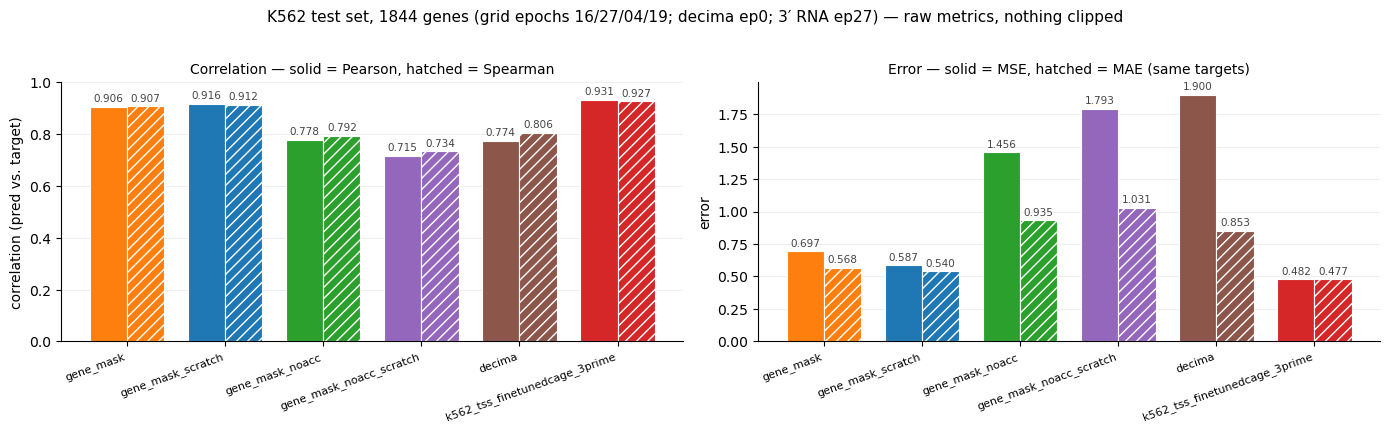

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(NAMES))
w = 0.38

ax = axes[0]
for off, key, hatch in [(-w / 2, "pearson", None), (w / 2, "spearman", "///")]:
    vals = [stats_[n][key] for n in NAMES]
    ax.bar(x + off, vals, w, color=[COLORS[n] for n in NAMES],
           hatch=hatch, edgecolor="white", linewidth=0.8)
    for xi, v in zip(x + off, vals):
        ax.text(xi, v + 0.012, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5, color="#444")
ax.set_ylim(0, 1.0)
ax.set_ylabel("correlation (pred vs. target)")
ax.set_title("Correlation — solid = Pearson, hatched = Spearman", fontsize=10)

ax = axes[1]
for off, key, hatch in [(-w / 2, "mse", None), (w / 2, "mae", "///")]:
    vals = [stats_[n][key] for n in NAMES]
    ax.bar(x + off, vals, w, color=[COLORS[n] for n in NAMES],
           hatch=hatch, edgecolor="white", linewidth=0.8)
    for xi, v in zip(x + off, vals):
        ax.text(xi, v + 0.02, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5, color="#444")
ax.set_ylabel("error")
ax.set_title("Error — solid = MSE, hatched = MAE (same targets)", fontsize=10)

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(NAMES, rotation=20, ha="right", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)

fig.suptitle(f"K562 test set, {len(common)} genes (grid epochs 16/27/04/19; decima ep0; 3′ RNA ep27) — raw metrics, "
             "nothing clipped", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()


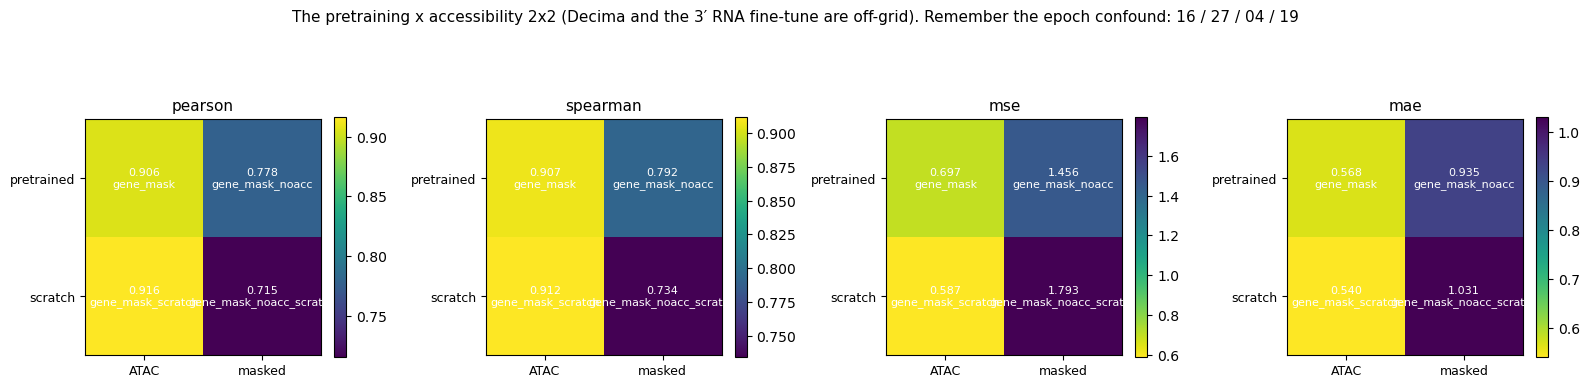

main effects on Pearson r (positive = the first term is better):
  pretrained - scratch, ATAC     accessibility : -0.0106
  pretrained - scratch, masked   accessibility : +0.0625
  ATAC - masked,        pretrained init        : +0.1278
  ATAC - masked,        scratch    init        : +0.2009


In [4]:
# The 2x2 read directly: pretraining on one axis, accessibility input on the other. This is the
# figure the four grid runs exist to produce; Decima and the 3′ RNA fine-tune are outside the grid.
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
CELL = {("pretrained", "ATAC"): "gene_mask", ("scratch", "ATAC"): "gene_mask_scratch",
        ("pretrained", "masked"): "gene_mask_noacc",
        ("scratch", "masked"): "gene_mask_noacc_scratch"}
inits, accs = ["pretrained", "scratch"], ["ATAC", "masked"]

for ax, key in zip(axes, ["pearson", "spearman", "mse", "mae"]):
    M = np.array([[stats_[CELL[(i, a)]][key] for a in accs] for i in inits])
    # correlations: high is good, so reverse the colormap for the two error metrics
    im = ax.imshow(M, cmap="viridis" if key in ("pearson", "spearman") else "viridis_r")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{M[i, j]:.3f}\n{CELL[(inits[i], accs[j])]}", ha="center", va="center",
                    fontsize=8, color="white")
    ax.set_xticks([0, 1]); ax.set_xticklabels(accs, fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(inits, fontsize=9)
    ax.set_title(key, fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("The pretraining x accessibility 2x2 (Decima and the 3′ RNA fine-tune are off-grid). Remember the epoch "
             "confound: 16 / 27 / 04 / 19", fontsize=11, y=1.06)
fig.tight_layout()
plt.show()

# the two main effects, read off the grid rather than eyeballed
print("main effects on Pearson r (positive = the first term is better):")
for a in accs:
    d = stats_[CELL[("pretrained", a)]]["pearson"] - stats_[CELL[("scratch", a)]]["pearson"]
    print(f"  pretrained - scratch, {a:8s} accessibility : {d:+.4f}")
for i in inits:
    d = stats_[CELL[(i, "ATAC")]]["pearson"] - stats_[CELL[(i, "masked")]]["pearson"]
    print(f"  ATAC - masked,        {i:10s} init        : {d:+.4f}")


## 2. Distribution of predicted and observed values

Target drawn once as a filled gray reference — it is identical for all six. The right panel is
the residual distribution: a shift off zero is bias, a wide spread is variance. Both panels are
clipped (see `PLOT_LIM`); the legend carries the number of genes each model puts outside the axis,
which for `decima` is where its raw MSE comes from.


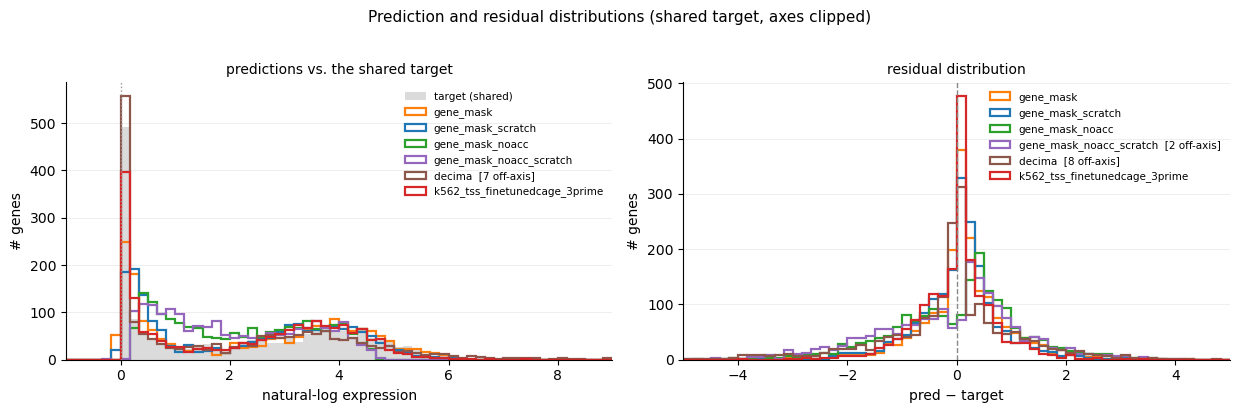

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
bins = np.linspace(*PLOT_LIM, 61)

ax = axes[0]
# target drawn once as a filled reference: it is identical for all six models
ax.hist(ref_t, bins=bins, color="#cccccc", alpha=0.7, label="target (shared)", zorder=0)
for name in NAMES:
    n_off = n_offscale(runs[name]["p"])
    ax.hist(runs[name]["p"], bins=bins, histtype="step", linewidth=1.6,
            color=COLORS[name], label=name + (f"  [{n_off} off-axis]" if n_off else ""))
ax.axvline(0, color="#999", linestyle=":", linewidth=1.0)
ax.set_xlim(PLOT_LIM)
ax.set_xlabel("natural-log expression")
ax.set_ylabel("# genes")
ax.set_title("predictions vs. the shared target", fontsize=10)
ax.legend(frameon=False, fontsize=7.5)

ax = axes[1]
resid_lim = (-5, 5)
for name in NAMES:
    resid = runs[name]["p"] - ref_t
    n_off = n_offscale(resid, resid_lim)
    ax.hist(resid, bins=np.linspace(*resid_lim, 61), histtype="step",
            linewidth=1.6, color=COLORS[name],
            label=name + (f"  [{n_off} off-axis]" if n_off else ""))
ax.axvline(0, color="#888", linestyle="--", linewidth=1.0)
ax.set_xlim(resid_lim)
ax.set_xlabel("pred − target")
ax.set_ylabel("# genes")
ax.set_title("residual distribution", fontsize=10)
ax.legend(frameon=False, fontsize=7.5)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)

fig.suptitle("Prediction and residual distributions (shared target, axes clipped)",
             fontsize=11, y=1.02)
fig.tight_layout()
plt.show()


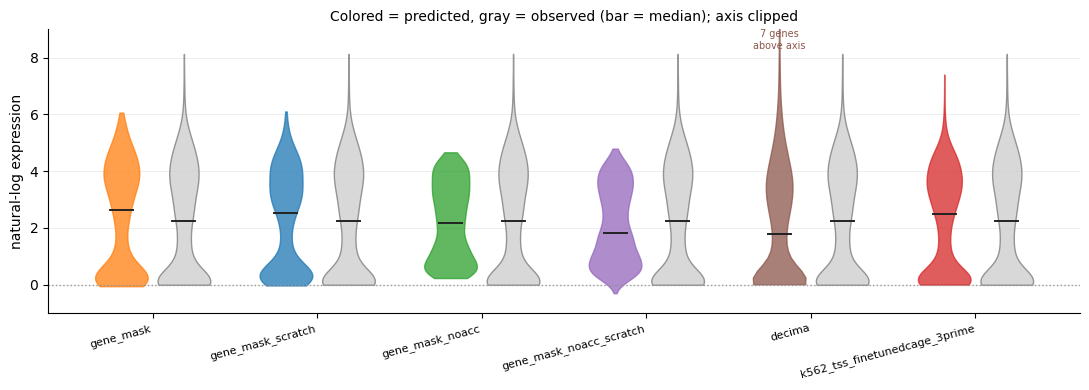

In [6]:
# Same information as paired violins: for each run, predicted vs. observed spread. The violins are
# computed on the full data and the axis is clipped afterwards, so the kernel is not distorted --
# only the view is cut.
fig, ax = plt.subplots(figsize=(11, 4))

positions, data, face, edge = [], [], [], []
for i, name in enumerate(NAMES):
    positions += [i - 0.19, i + 0.19]
    data += [runs[name]["p"], runs[name]["t"]]
    face += [COLORS[name], "#cccccc"]
    edge += [COLORS[name], "#777777"]

parts = ax.violinplot(data, positions=positions, widths=0.32, showextrema=False)
for body, fc, ec in zip(parts["bodies"], face, edge):
    body.set_facecolor(fc)
    body.set_edgecolor(ec)
    body.set_alpha(0.75)
    body.set_linewidth(1.0)

for pos, arr in zip(positions, data):
    ax.plot([pos - 0.07, pos + 0.07], [np.median(arr)] * 2, color="#222", linewidth=1.4)

for i, name in enumerate(NAMES):
    n_off = n_offscale(runs[name]["p"])
    if n_off:
        ax.annotate(f"{n_off} genes\nabove axis", xy=(i - 0.19, PLOT_LIM[1]), fontsize=7,
                    ha="center", va="top", color=COLORS[name])

ax.axhline(0, color="#999", linestyle=":", linewidth=1.0)
ax.set_ylim(PLOT_LIM)
ax.set_xticks(np.arange(len(NAMES)))
ax.set_xticklabels(NAMES, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("natural-log expression")
ax.set_title("Colored = predicted, gray = observed (bar = median); axis clipped", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


## 3. Predicted vs. observed, per run

Density-colored scatter; dashed line is `y = x`. All six panels share the same clipped axes, so
they are overlayable by eye. The panel title carries each model's raw metrics (computed on every
gene) and the count of genes pushed off the axis.


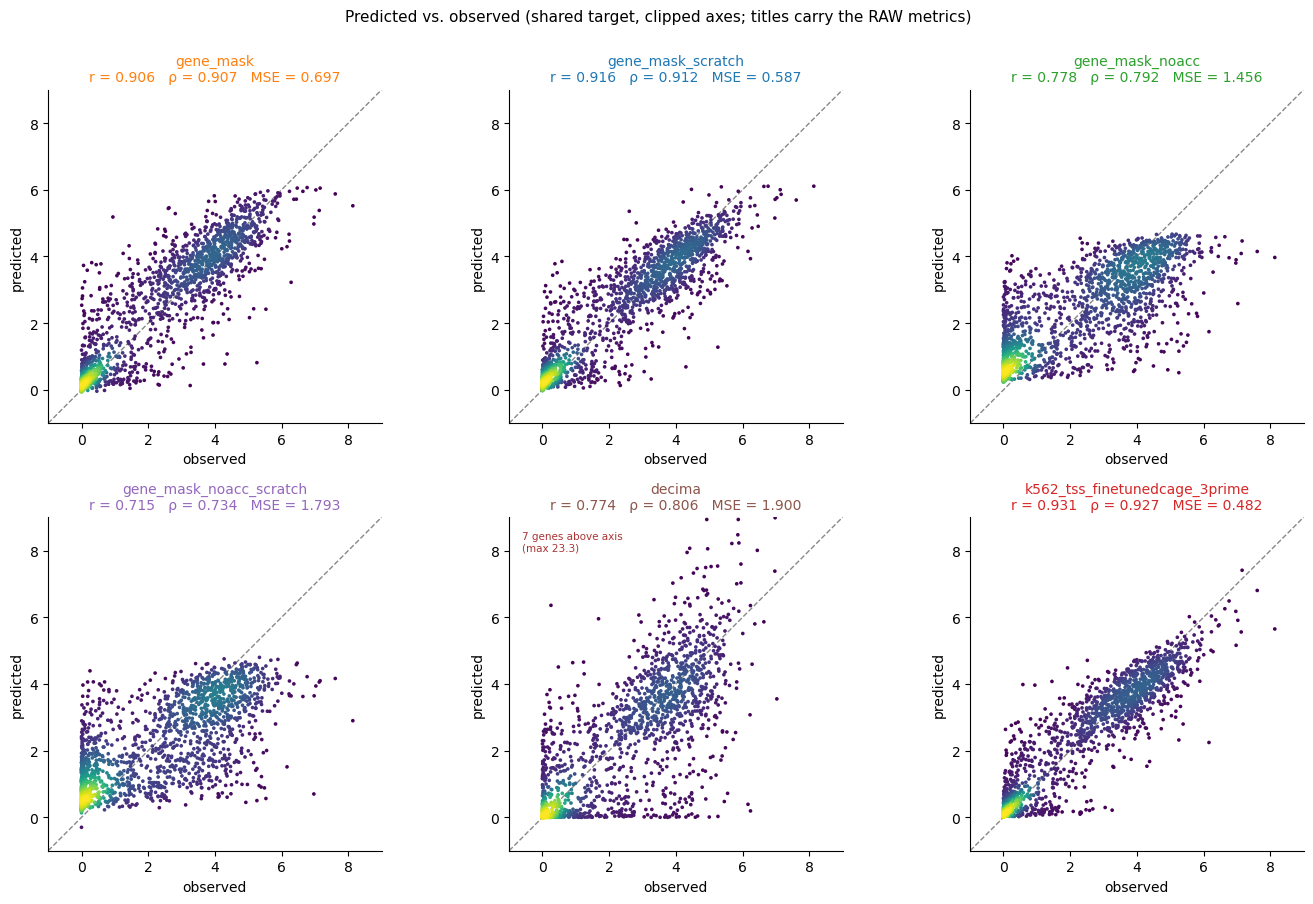

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for ax, name in zip(axes.ravel(), NAMES):
    t, p = runs[name]["t"], runs[name]["p"]
    dens = gaussian_kde(np.vstack([t, p]))(np.vstack([t, p]))
    order = dens.argsort()  # draw dense points last so they are not buried
    ax.scatter(t[order], p[order], c=dens[order], s=7, cmap="viridis", linewidths=0)

    ax.plot(PLOT_LIM, PLOT_LIM, "--", color="#888", linewidth=1.0, zorder=0)
    ax.set_xlim(PLOT_LIM)
    ax.set_ylim(PLOT_LIM)
    ax.set_aspect("equal")

    n_off = n_offscale(p)
    if n_off:
        ax.annotate(f"{n_off} genes above axis\n(max {p.max():.1f})", xy=(0.04, 0.96),
                    xycoords="axes fraction", fontsize=7.5, va="top", color="#a33")

    s = stats_[name]
    ax.set_title(f"{name}\nr = {s['pearson']:.3f}   ρ = {s['spearman']:.3f}   MSE = {s['mse']:.3f}",
                 fontsize=10, color=COLORS[name])
    ax.set_xlabel("observed")
    ax.set_ylabel("predicted")
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.ravel()[len(NAMES):]:
    ax.set_visible(False)
fig.suptitle("Predicted vs. observed (shared target, clipped axes; titles carry the RAW metrics)",
             fontsize=11, y=1.0)
fig.tight_layout()
plt.show()


## 4. Model vs. model

Pairwise agreement as a matrix (Pearson below the diagonal is the same as above — it is drawn
symmetric, with Spearman in the second panel). All six are in natural log, so no rescaling is
needed; the matrix is computed on the raw predictions, tail included, so `decima`'s row is
depressed by the same handful of genes that depress its raw Pearson in §1.

The four scatters after it are the **edges of the 2x2** — each isolates exactly one factor:
the two vertical edges change the backbone init at fixed accessibility, the two horizontal edges
change the accessibility input at fixed init.


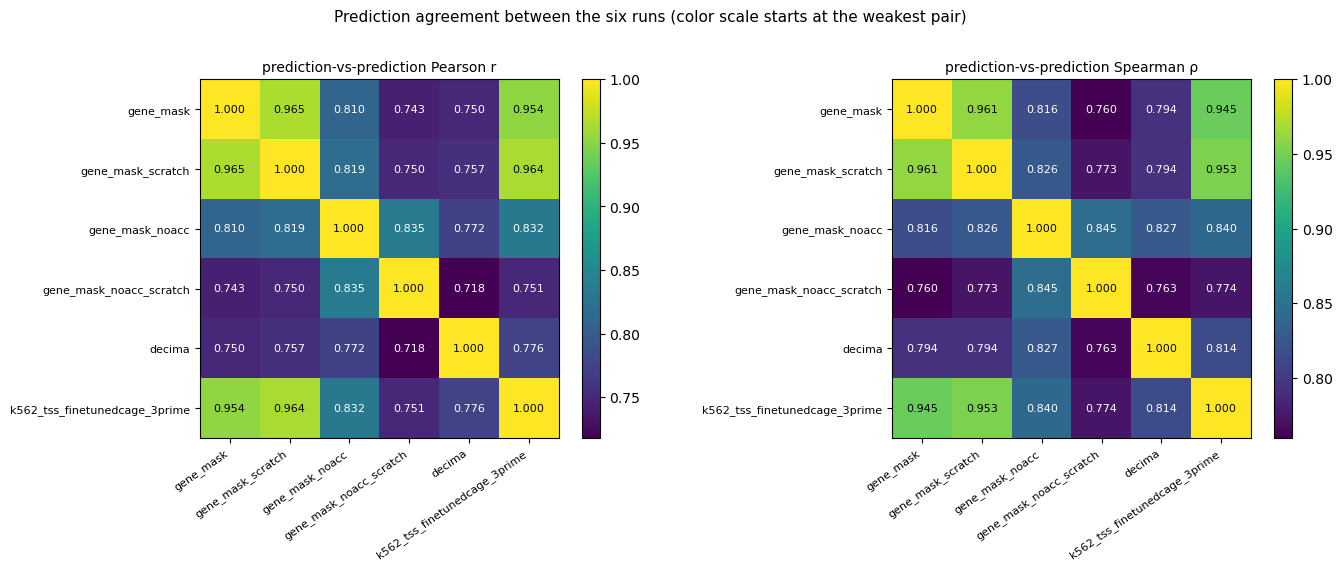

In [8]:
# Pairwise prediction agreement as a matrix.
P = np.vstack([runs[n]["p"] for n in NAMES])
r_mat = np.corrcoef(P)
rho_mat = spearmanr(P, axis=1).statistic

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, M, label in [(axes[0], r_mat, "Pearson r"), (axes[1], rho_mat, "Spearman ρ")]:
    off_diag = M[~np.eye(len(NAMES), dtype=bool)]
    im = ax.imshow(M, cmap="viridis", vmin=off_diag.min(), vmax=1.0)
    for i in range(len(NAMES)):
        for j in range(len(NAMES)):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if M[i, j] < off_diag.min() + 0.6 * (1 - off_diag.min())
                    else "black")
    ax.set_xticks(np.arange(len(NAMES)))
    ax.set_xticklabels(NAMES, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(np.arange(len(NAMES)))
    ax.set_yticklabels(NAMES, fontsize=8)
    ax.set_title(f"prediction-vs-prediction {label}", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("Prediction agreement between the six runs (color scale starts at the weakest pair)",
             fontsize=11, y=1.01)
fig.tight_layout()
plt.show()


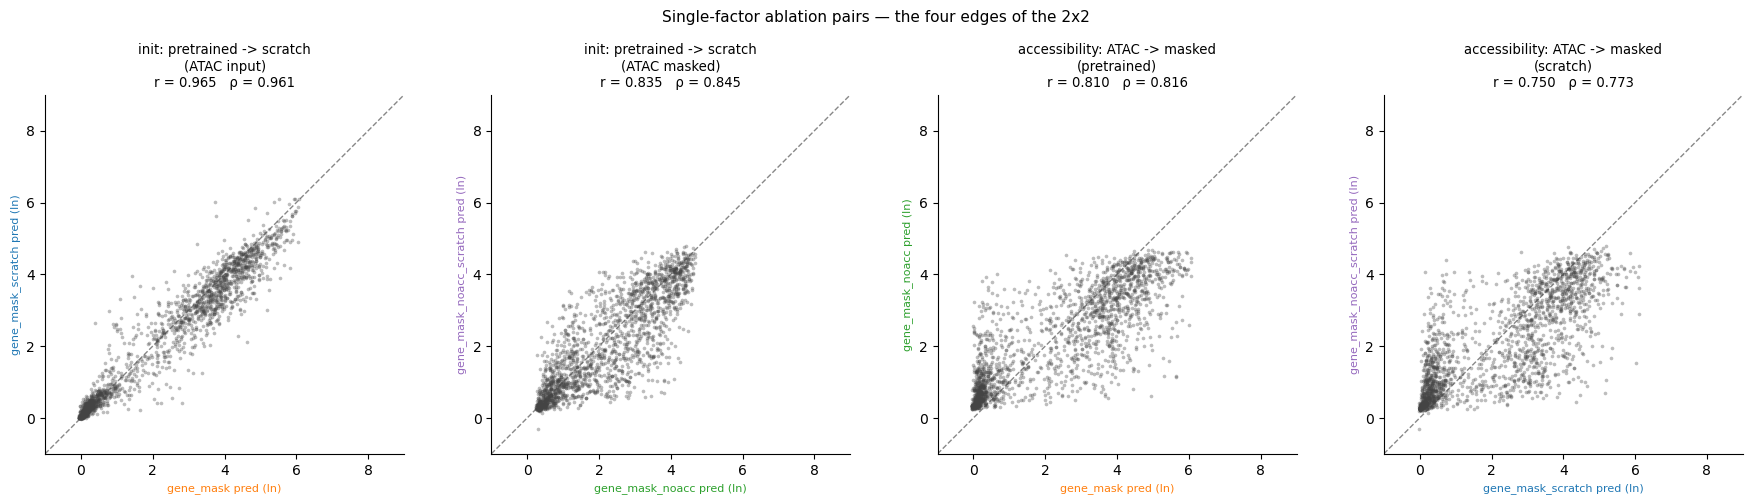

In [9]:
# The four edges of the 2x2. Each changes exactly one factor; axes are clipped, and the r/rho in
# the title are computed on the unclipped predictions.
ABLATION_PAIRS = [
    ("gene_mask", "gene_mask_scratch", "init: pretrained -> scratch\n(ATAC input)"),
    ("gene_mask_noacc", "gene_mask_noacc_scratch", "init: pretrained -> scratch\n(ATAC masked)"),
    ("gene_mask", "gene_mask_noacc", "accessibility: ATAC -> masked\n(pretrained)"),
    ("gene_mask_scratch", "gene_mask_noacc_scratch", "accessibility: ATAC -> masked\n(scratch)"),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (a, b, what) in zip(axes, ABLATION_PAIRS):
    pa, pb = runs[a]["p"], runs[b]["p"]
    ax.scatter(pa, pb, s=7, alpha=0.35, color="#444", linewidths=0)

    ax.plot(PLOT_LIM, PLOT_LIM, "--", color="#888", linewidth=1.0, zorder=0)
    ax.set_xlim(PLOT_LIM)
    ax.set_ylim(PLOT_LIM)
    ax.set_aspect("equal")

    r = np.corrcoef(pa, pb)[0, 1]
    rho = spearmanr(pa, pb).statistic
    ax.set_title(f"{what}\nr = {r:.3f}   ρ = {rho:.3f}", fontsize=9.5)
    ax.set_xlabel(f"{a} pred (ln)", color=COLORS[a], fontsize=8)
    ax.set_ylabel(f"{b} pred (ln)", color=COLORS[b], fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Single-factor ablation pairs — the four edges of the 2x2", fontsize=11, y=1.03)
fig.tight_layout()
plt.show()


### 4b. Per-gene head-to-head

For each gene, which model is closest? A model can win on aggregate MSE while losing on most
individual genes (a few large misses dominate the mean), so the win rate and the aggregate metric
answer different questions — and `decima` is exactly the case that separates them.


share of genes where each model has the smallest |error| of the six:
  gene_mask                           18.3%
  gene_mask_scratch                   15.1%
  gene_mask_noacc                      8.0%
  gene_mask_noacc_scratch              9.3%
  decima                              28.9%
  k562_tss_finetunedcage_3prime       20.4%

pairwise win rate (row model closer than column model, per gene):
                                             gene_mask   gene_mask_scratch     gene_mask_noacc  gene_mask_noacc_sc              decima  k562_tss_finetuned
gene_mask                                                           51.0%               69.7%               70.6%               52.6%               42.8% 
gene_mask_scratch                               49.0%                                   71.6%               73.4%               52.2%               42.3% 
gene_mask_noacc                                 30.3%               28.4%                                   52.9%               40.2%  

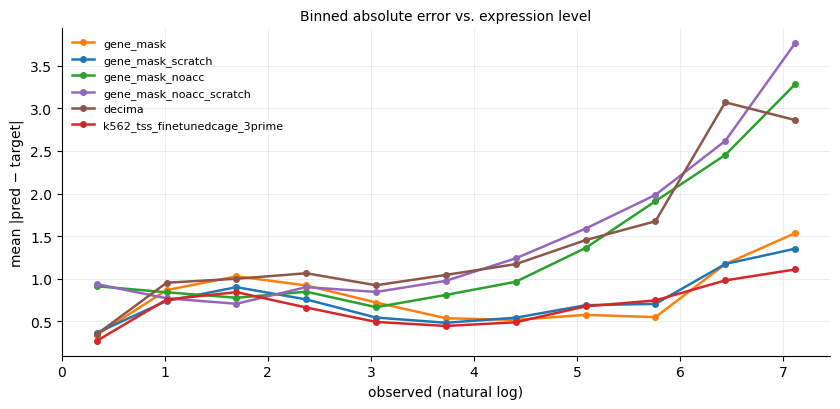

In [10]:
abs_err = {n: np.abs(runs[n]["p"] - ref_t) for n in NAMES}
best = np.vstack([abs_err[n] for n in NAMES]).argmin(axis=0)

print("share of genes where each model has the smallest |error| of the six:")
for i, n in enumerate(NAMES):
    print(f"  {n:34s}{(best == i).mean():7.1%}")

print("\npairwise win rate (row model closer than column model, per gene):")
print(f"{'':34s}" + "".join(f"{n[:18]:>20s}" for n in NAMES))
for a in NAMES:
    row = ["".ljust(20) if a == b else f"{(abs_err[a] < abs_err[b]).mean():19.1%} "
           for b in NAMES]
    print(f"{a:34s}" + "".join(row))

# Where in the expression range each model wins or loses -- the aggregate MSE hides this.
fig, ax = plt.subplots(figsize=(8.5, 4.2))
edges = np.linspace(ref_t.min(), ref_t.max(), 13)
centers = 0.5 * (edges[:-1] + edges[1:])
for n in NAMES:
    means = [abs_err[n][(ref_t >= lo) & (ref_t < hi)].mean()
             if ((ref_t >= lo) & (ref_t < hi)).sum() > 3 else np.nan
             for lo, hi in zip(edges[:-1], edges[1:])]
    ax.plot(centers, means, color=COLORS[n], linewidth=1.8, marker="o", markersize=4, label=n)
ax.set_xlabel("observed (natural log)")
ax.set_ylabel("mean |pred − target|")
ax.set_title("Binned absolute error vs. expression level", fontsize=10)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


## 5. Per-chromosome correlation

Checks whether any single test chromosome drives the overall numbers.


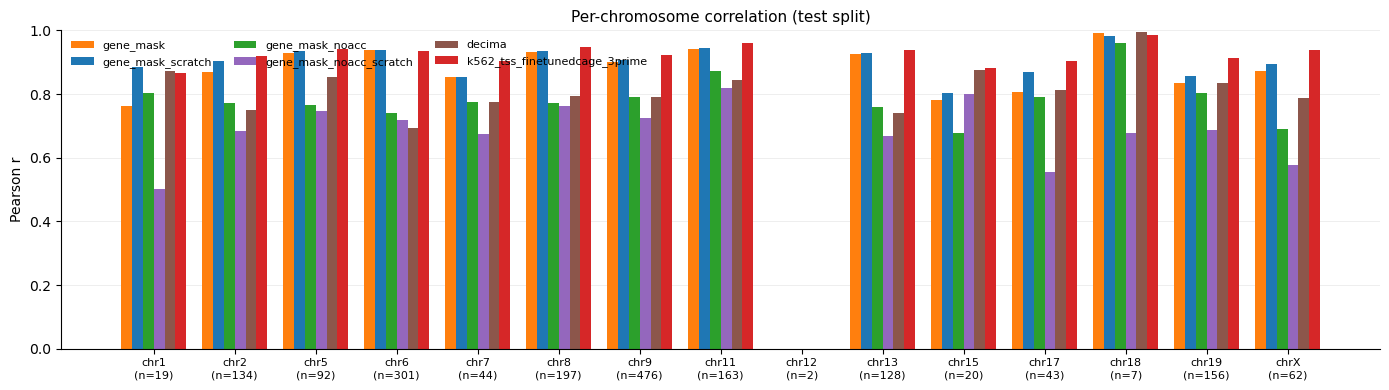

In [11]:
chroms = sorted(set(runs[NAMES[0]]["chrom"].tolist()),
                key=lambda c: (c == "chrX", int(c[3:]) if c[3:].isdigit() else 99))
counts = [int((runs[NAMES[0]]["chrom"] == c).sum()) for c in chroms]

fig, ax = plt.subplots(figsize=(14, 4.0))
w = 0.8 / len(NAMES)
for i, name in enumerate(NAMES):
    r = runs[name]
    vals = []
    for c in chroms:
        m = r["chrom"] == c
        vals.append(float(np.corrcoef(r["p"][m], r["t"][m])[0, 1]) if m.sum() > 2 else np.nan)
    ax.bar(np.arange(len(chroms)) + (i - (len(NAMES) - 1) / 2) * w, vals, w, color=COLORS[name], label=name)

ax.set_xticks(np.arange(len(chroms)))
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(chroms, counts)], fontsize=8)
ax.set_ylabel("Pearson r")
ax.set_ylim(0, 1.0)
ax.set_title("Per-chromosome correlation (test split)", fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


## 6. Where the error lives

Signed residual (`pred − target`) against observed expression. A downward trend means the model
over-predicts silent genes and under-predicts highly expressed ones — regression toward the mean.
The y axis is clipped; the binned mean (black) is computed on the unclipped residuals, so a black
point can sit outside the visible cloud where a model has off-axis genes in that bin.


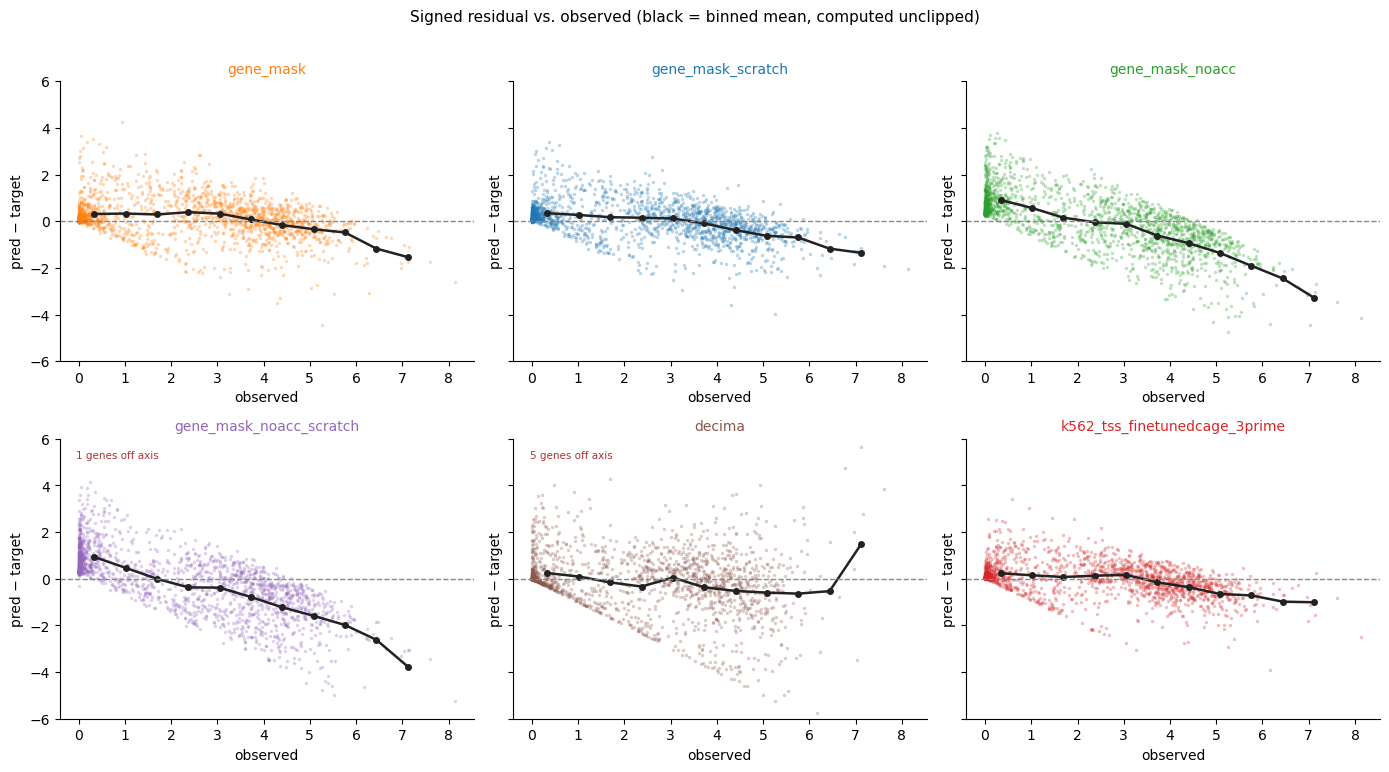

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.6), sharey=True)

for ax, name in zip(axes.ravel(), NAMES):
    t, p = runs[name]["t"], runs[name]["p"]
    resid = p - t
    ax.scatter(t, resid, s=6, alpha=0.3, color=COLORS[name], linewidths=0)

    # binned mean residual, to make the trend readable through the point cloud
    edges = np.linspace(t.min(), t.max(), 13)
    centers = 0.5 * (edges[:-1] + edges[1:])
    means = [resid[(t >= lo) & (t < hi)].mean() if ((t >= lo) & (t < hi)).sum() > 3 else np.nan
             for lo, hi in zip(edges[:-1], edges[1:])]
    ax.plot(centers, means, color="#222", linewidth=1.8, marker="o", markersize=4)

    ax.axhline(0, color="#888", linestyle="--", linewidth=1.0)
    ax.set_ylim(-6, 6)
    n_off = n_offscale(resid, (-6, 6))
    if n_off:
        ax.annotate(f"{n_off} genes off axis", xy=(0.04, 0.96), xycoords="axes fraction",
                    fontsize=7.5, va="top", color="#a33")
    ax.set_xlabel("observed")
    ax.set_ylabel("pred − target")
    ax.set_title(name, fontsize=10, color=COLORS[name])
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.ravel()[len(NAMES):]:
    ax.set_visible(False)
fig.suptitle("Signed residual vs. observed (black = binned mean, computed unclipped)",
             fontsize=11, y=1.01)
fig.tight_layout()
plt.show()


## 7. Rank profile

Genes sorted by observed expression with the prediction overlaid. The ordering is identical across
panels, so the traces can be compared position by position.


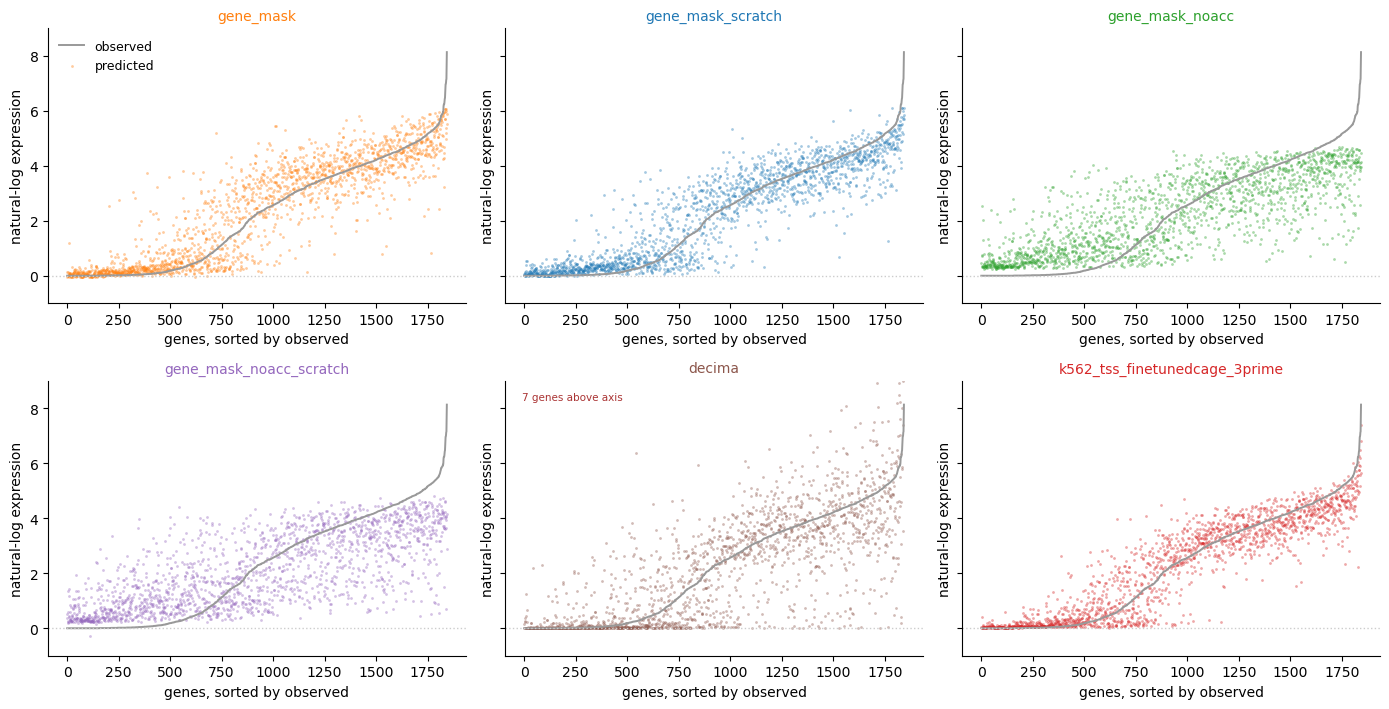

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharey=True)

for ax, name in zip(axes.ravel(), NAMES):
    t, p = runs[name]["t"], runs[name]["p"]
    order = np.argsort(t)
    xs = np.arange(len(order))
    ax.plot(xs, t[order], color="#999", linewidth=1.4, label="observed")
    ax.scatter(xs, p[order], s=4, alpha=0.4, color=COLORS[name], linewidths=0, label="predicted")
    ax.axhline(0, color="#ccc", linestyle=":", linewidth=1.0)
    ax.set_ylim(PLOT_LIM)
    n_off = n_offscale(p)
    if n_off:
        ax.annotate(f"{n_off} genes above axis", xy=(0.04, 0.96), xycoords="axes fraction",
                    fontsize=7.5, va="top", color="#a33")
    ax.set_xlabel("genes, sorted by observed")
    ax.set_ylabel("natural-log expression")
    ax.set_title(name, fontsize=10, color=COLORS[name])
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.ravel()[len(NAMES):]:
    ax.set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
plt.show()


## 8. Enhancer–gene linking (ENCODE CRISPR benchmark)

All six models appear here; §8–§8e use the scalar count/expression readouts. **Decima uses epoch 0**, matching the expression
comparisons above, and participates in the sequence-shuffle arm only.

| arm | perturbation | models |
|---|---|---|
| `acc` | accessibility ÷ 100 over the element ± 100 bp | `gene_mask`, `gene_mask_scratch`, `k562_tss_finetunedcage_3prime` (count head) |
| `shuffle` | element ± 100 bp dinucleotide-shuffled 11 times | `gene_mask`, `gene_mask_scratch`, `gene_mask_noacc`, `gene_mask_noacc_scratch`, `decima` (epoch 0) |

Decima takes DNA and a gene-body mask, with no accessibility input. Only DNA is
shuffled; the gene mask stays fixed. The noacc models receive fully masked
accessibility, so an accessibility knockdown would be a no-op. `gene_mask` and
`gene_mask_scratch` each have both perturbation arms.

**New in this round:** `k562_tss_sc_decima_scratch_ep27_dinuc` (task 13 of
`evals/evaluate_e2g_tss_dn.sh`, same checkpoint `27-val_loss=0.68757` as the `acc` run,
`--perturbation shuffle --n_shuffles 11 --dist_additional_shuffle 100 --seed 0`). It was the
missing cell: the `shuffle` arm now carries the **complete pretraining × accessibility 2×2**
under one protocol, which §8a-bis reads off directly. Note this is the real-ATAC scratch model
scored with a sequence perturbation — accessibility is an ordinary input to it, not masked.

### Comparisons

- Within `shuffle`, all four grid cells are now present, so pretraining and the
  accessibility input can each be isolated at fixed levels of the other (§8a-bis).
  The two noacc models compare pretraining with accessibility withheld;
  `gene_mask` versus `gene_mask_scratch` compares it with real ATAC;
  `gene_mask` versus `gene_mask_noacc` compares accessibility inputs at fixed
  pretraining. Decima epoch 0 provides a separate architecture comparison
  under the same shuffle protocol; it does not isolate pretraining alone.
- Within `acc`, `gene_mask` versus `gene_mask_scratch` compares pretraining with real ATAC.
  That pair is now also available in the `shuffle` arm, so the two arms can be asked whether
  they agree on the sign of the pretraining effect — without pooling their magnitudes.
- Keep comparisons between different perturbation arms separate.

### Inputs and scoring

1. All eight runs use the same gene JSON and benchmark pairs: 10306 pairs,
   with 3914 in context under the 524288 bp, 163840 upstream, strand-oriented
   window. The loader checks masks and Decima's saved pair identities. The new TSV is
   aligned by `pair_id`, with gene IDs, labels, coordinates, and effect sizes checked.
2. Decima files are read directly from
   `/data1/lesliec/sarthak/decima/runs/e2g/k562_decima_borzoi_ep0_dinuc*`.
   Rerun after the evaluation finishes; missing files produce a clear error.
3. Column 0 is the reference and columns 1–11 are individual shuffled predictions.
   All outputs are on the natural-log expression target scale. For Decima this is
   `exp(model logits)`, already applied by the evaluation script; do not exponentiate again.
   The grid models use plain regression outputs, which can be negative.
4. `score = mean(shuffles) - reference`: negative means predicted repression.
   Mean differences equal the difference of means on this scale. All 11 shuffles
   are retained to compute the per-element noise floor (sample standard deviation).
5. The loader checks, for every model present in both arms, that the unperturbed reference
   predictions agree bit-for-bit between them.
   Context comes from the stored mask, not from a nonzero-score test.
6. `DistanceToTSS` is left-mapped from rE2G, preserving benchmark order and length.
7. The 3′ RNA fine-tune is loaded from `k562_tss_finetunedcage_3prime/scores.tsv`.
   Its count score is `count_after - count_before` in natural-log units, equivalent to
   the saved `delta_scalar_count * ln(2)`. The TSV deltas themselves are in log2 units.
   Only its 3914 in-context links were evaluated: out-of-context NaNs are preserved.
   Its all-pair metrics are unavailable; it appears in the matched in-context comparisons.
   No shuffle evaluation is available for this model. §8f compares its count and native
   gene-body profile readouts on the same 3875 full-gene links, alongside the existing
   accessibility-arm models restricted to those exact links.


In [14]:
# --- Load the E2G runs: two arms, six models --------------------------------------------------
# Self-contained: re-imports and re-declares everything it uses.
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

E2G_DIR = "/data1/lesliec/sarthak/data/joint_playground/e2g"
DECIMA_E2G_DIR = "/data1/lesliec/sarthak/decima/runs/e2g"
RNA_INFO_DIR = "/data1/lesliec/sarthak/data/DE_danwei"
TSS_BOUNDS_FILE = "/data1/deyk/extras/CollapsedGeneBounds.hg38.TSS500bp.bed"
CRISPR_FILE = "/data1/deyk/ENCODE/CRISPR/EPCrisprBenchmark_ensemble_data_GRCh38.tsv"
RE2G_FILE = (f"{E2G_DIR}/ENCODE-rE2G_extended_CrossValidated_K562_"
             "EPCrisprBenchmark_ensemble_data_GRCh38.predictions.tsv.gz")
SHARED_JSON = "k562_sc_rna_info_cellranger.json"     # gene filter, identical for all six

# Legacy (model, arm) -> stem of the .npy pair in e2g/. The arm each model gets is forced by its training:
# the two noacc models have a fully masked accessibility track, so an accessibility knockdown is a
# bit-exact no-op on them and only a sequence perturbation says anything. The two models that do
# receive real ATAC (gene_mask, gene_mask_scratch) are run in both arms.
E2G_RUNS = {
    ("gene_mask", "acc"):                   "k562_decima_2",
    ("gene_mask_scratch", "acc"):           "k562_tss_sc_decima_scratch_ep27",
    ("gene_mask", "shuffle"):               "k562_decima_2_dinuc",
    # newest output in e2g/ (2026-09-20): same ckpt as the scratch acc run, shuffle protocol.
    # It completes the 2x2 inside the shuffle arm -- see 8a-bis.
    ("gene_mask_scratch", "shuffle"):       "k562_tss_sc_decima_scratch_ep27_dinuc",
    ("gene_mask_noacc", "shuffle"):         "k562_tss_sc_decima_noacc_ep04_dinuc",
    ("gene_mask_noacc_scratch", "shuffle"): "k562_tss_sc_decima_noacc_scratch_ep19_dinuc",
    ("decima", "shuffle"):                  "k562_decima_borzoi_ep0_dinuc",
}
FINETUNED = "k562_tss_finetunedcage_3prime"
FINETUNED_DIR = Path(E2G_DIR) / FINETUNED
RUN_KEYS = list(E2G_RUNS) + [(FINETUNED, "acc")]
ARMS = ["acc", "shuffle"]
ARM_MODELS = {arm: [m for (m, a) in RUN_KEYS if a == arm] for arm in ARMS}
ARM_LABEL = {"acc": "accessibility /100", "shuffle": "dinuc shuffle (11x)"}
ARM_LS = {"acc": "-", "shuffle": "--"}
N_SHUFFLES = 11          # --n_shuffles in evals/evaluate_e2g_tss_dn.sh

# Repeated so this section runs standalone; Decima is always epoch 0.
COLORS = {
    "gene_mask":               "#ff7f0e",
    "gene_mask_scratch":       "#1f77b4",
    "gene_mask_noacc":         "#2ca02c",
    "gene_mask_noacc_scratch": "#9467bd",
    "decima":                  "#8c564b",
    "k562_tss_finetunedcage_3prime": "#d62728",
}


def run_label(key):
    name = "decima ep0" if key[0] == "decima" else key[0]
    return f"{name} [{key[1]}]"


tss_bounds = pd.read_csv(TSS_BOUNDS_FILE, sep="\t")
crispr = pd.read_csv(CRISPR_FILE, sep="\t")
crispr["master"] = (crispr["chrom"] + ":" + crispr["chromStart"].astype(str) + "-"
                    + crispr["chromEnd"].astype(str) + "_" + crispr["measuredGeneSymbol"])
assert crispr["master"].is_unique, "master must be unique to key the models against each other"

re2g = pd.read_csv(RE2G_FILE, sep="\t")
re2g["master"] = (re2g["chr"] + ":" + re2g["start"].astype(str) + "-"
                  + re2g["end"].astype(str) + "_" + re2g["TargetGene"])
assert re2g["master"].is_unique, "rE2G master keys must be unique for a left merge to stay aligned"
dist_by_master = re2g.set_index("master")["DistanceToTSS"]


def build_gs(json_name):
    '''The gene filter from evals/e2g_tss.py, for one rna_info json.'''
    with open(f"{RNA_INFO_DIR}/{json_name}") as f:
        tss_dict = json.load(f)
    name_to_ensg = tss_bounds.set_index("name")["Ensembl_ID"].to_dict()
    name_to_ensg = {n: e for n, e in name_to_ensg.items() if e in tss_dict}
    g = crispr.copy()
    g["ensg_id"] = g["measuredGeneSymbol"].map(name_to_ensg)
    return g.dropna(subset=["ensg_id", "Regulated"]).reset_index(drop=True)


gs = build_gs(SHARED_JSON)
# left merge keeps gs order and length; pairs absent from rE2G become NaN and drop out of the
# distance-stratified panels only
dist = gs["master"].map(dist_by_master).values.astype(float)
y_true = gs["Regulated"].astype(int).values
effect = gs["EffectSize"].values

e2g = {}
for key, stem in E2G_RUNS.items():
    arm = key[1]
    directory = DECIMA_E2G_DIR if key[0] == "decima" else E2G_DIR
    prefix = Path(directory) / stem
    required = [".npy", "_in_context.npy"]
    if arm == "shuffle":
        required.append("_shuffled.npy")
    if key[0] == "decima":
        required.extend(["_pairs.tsv", "_args.json"])
    missing = [str(prefix) + suffix for suffix in required
               if not Path(str(prefix) + suffix).is_file()]
    if missing:
        raise FileNotFoundError(f"{run_label(key)}: missing {missing}. "
                                "Rerun after the evaluation job finishes.")
    outputs = np.load(f"{prefix}.npy")
    in_context = np.load(f"{prefix}_in_context.npy")
    if key[0] == "decima":
        saved_pairs = pd.read_csv(f"{prefix}_pairs.tsv", sep="\t")
        pair_cols = ["chrom", "chromStart", "chromEnd", "measuredGeneSymbol", "ensg_id", "Regulated"]
        pd.testing.assert_frame_equal(saved_pairs[pair_cols], gs[pair_cols], check_dtype=False)
        with open(f"{prefix}_args.json") as handle:
            decima_args = json.load(handle)
        assert Path(decima_args["ckpt_path"]).name == "epoch=0-step=462.ckpt", "Expected Decima epoch 0"
        assert decima_args["n_shuffles"] == N_SHUFFLES and decima_args["save_all_shuffles"]
        assert decima_args["dist_additional_shuffle"] == 100 and decima_args["seed"] == 0
    assert outputs.ndim == 2 and np.isfinite(outputs).all(), f"{run_label(key)}: invalid outputs"
    assert in_context.shape == (len(gs),), f"{run_label(key)}: invalid context mask"
    assert len(outputs) == len(gs), f"{run_label(key)}: {len(outputs)} outputs vs {len(gs)} pairs"
    if arm == "acc":
        # e2g_tss.py wrote two columns, [before, after]; there is no shuffle spread
        assert outputs.shape[1] == 2, f"{run_label(key)}: expected 2 columns"
        alt, sd, shuffled = outputs[:, 1], None, None
    else:
        # --save_all_shuffles: [before, shuf0 ... shuf10]. Average the shuffles HERE, in log space;
        # subtracting the reference before or after averaging gives the same log-space score.
        assert outputs.shape[1] == 1 + N_SHUFFLES, \
            f"{run_label(key)}: expected {1 + N_SHUFFLES} columns, got {outputs.shape[1]}"
        alt = outputs[:, 1:].mean(axis=1)
        sd = outputs[:, 1:].std(axis=1, ddof=1)          # per-element noise floor
        shuffled = np.load(f"{prefix}_shuffled.npy")
    e2g[key] = {
        "score": alt - outputs[:, 0],     # natural log space, so a plain difference
        "ref": outputs[:, 0],
        "sd": sd,
        "in_context": in_context,
        "shuffled": shuffled,
        "stem": stem,
    }

# New-format readout scores: join identities before extracting any arrays.
with open(FINETUNED_DIR / "status.json") as handle:
    finetuned_status = json.load(handle)
assert finetuned_status["status"] == "completed", "The 3′ RNA E2G evaluation is incomplete"
with open(FINETUNED_DIR / "protocol.json") as handle:
    finetuned_protocol = json.load(handle)
assert Path(finetuned_protocol["checkpoint"]) == Path(
    "/data1/lesliec/sarthak/caduceus/outputs/cage103_to_3prime_20260922/training/"
    "checkpoints/27-val_loss=0.53016.ckpt")
assert finetuned_protocol["scale_factor"] == 100 and finetuned_protocol["flank"] == 100
assert finetuned_protocol["pseudocount"] == 1
assert finetuned_protocol["target_transform"] == "sqrt(1+coverage)-1"
# Preserve serialized float precision so tied count deltas stay tied.
finetuned_scores = pd.read_csv(FINETUNED_DIR / "scores.tsv", sep="\t", float_precision="round_trip")
assert finetuned_scores["pair_id"].is_unique
assert set(finetuned_scores["pair_id"]) == set(gs["master"]), "E2G benchmark pair sets differ"
finetuned_scores = finetuned_scores.set_index("pair_id").loc[gs["master"]].reset_index()
pair_cols = ["chrom", "chromStart", "chromEnd", "measuredGeneSymbol", "ensg_id",
             "Regulated", "EffectSize"]
pd.testing.assert_frame_equal(finetuned_scores[pair_cols], gs[pair_cols], check_dtype=False)
finetuned_context = finetuned_scores["element_in_context"].to_numpy(bool)
finetuned_evaluated = finetuned_scores["evaluated"].to_numpy(bool)
np.testing.assert_array_equal(finetuned_evaluated, finetuned_context)
finetuned_count_score = (finetuned_scores["count_after"] - finetuned_scores["count_before"]).to_numpy()
np.testing.assert_array_equal(np.isfinite(finetuned_count_score), finetuned_evaluated)
np.testing.assert_allclose(
    finetuned_count_score[finetuned_evaluated],
    finetuned_scores.loc[finetuned_evaluated, "delta_scalar_count"].to_numpy() * np.log(2),
    rtol=1e-6, atol=1e-10)
e2g[(FINETUNED, "acc")] = {
    "score": finetuned_count_score,
    "ref": finetuned_scores["count_before"].to_numpy(),
    "sd": None,
    "in_context": finetuned_context,
    "shuffled": None,
    "stem": str(FINETUNED_DIR / "scores.tsv"),
}

# --- consistency checks ------------------------------------------------------------------------
ref_key = RUN_KEYS[0]
ic_ref = e2g[ref_key]["in_context"]
for key in RUN_KEYS[1:]:
    # all six models share the Decima window geometry, so in_context must be identical, not merely
    # the same size
    assert (e2g[key]["in_context"] == ic_ref).all(), \
        f"{run_label(key)} disagrees with {run_label(ref_key)} on in_context"
# gene_mask and gene_mask_scratch each appear in both arms, and their unperturbed forward pass is
# recomputed independently per arm (for gene_mask, by two different scripts -- e2g_tss.py and
# e2g_tss_profile_dn.py), so bit-equality of the reference column is a free determinism check
BOTH_ARMS = [m for m in ARM_MODELS["acc"] if m in ARM_MODELS["shuffle"]]
for m in BOTH_ARMS:
    assert (e2g[(m, "acc")]["ref"] == e2g[(m, "shuffle")]["ref"]).all(), \
        f"{m}: the acc and shuffle reference columns differ -- the harness is not deterministic"
for key in RUN_KEYS:
    if key[1] != "acc":
        # every in-context element was actually shuffled (none fell under --min_shuffle_len 10)
        assert (e2g[key]["shuffled"] == e2g[key]["in_context"]).all(), \
            f"{run_label(key)}: some in-context elements were not shuffled"

ctx = ic_ref                       # identical for every run
for key in RUN_KEYS:
    assert np.isfinite(e2g[key]["score"][ctx]).all(), f"{run_label(key)}: missing in-context scores"
print(f"{len(gs)} pairs, {int(y_true.sum())} regulated "
      f"(baseline AUPRC {y_true.mean():.4f})")
print(f"in context: {int(ctx.sum())} for every run "
      f"({int(y_true[ctx].sum())} regulated, baseline AUPRC {y_true[ctx].mean():.4f})")
print(f"models in both arms (reference columns verified bit-equal): {', '.join(BOTH_ARMS)}")
print("all six models share one window geometry, so no context intersection is needed")
print(f"{FINETUNED}: count head in these panels; out-of-context scores were not evaluated.\n")

print(f"{'run':38s}{'mean':>10s}{'std':>9s}{'% neg':>8s}{'mean |score|':>14s}"
      f"{'shuffle sd':>12s}{'|score|/sd':>12s}   (in context)")
for key in RUN_KEYS:
    d = e2g[key]
    s = d["score"][ctx]
    if d["sd"] is None:
        sd_str, ratio = f"{'--':>12s}", f"{'--':>12s}"
    else:
        sd_str = f"{d['sd'][ctx].mean():12.4f}"
        ratio = f"{np.mean(np.abs(s) / d['sd'][ctx]):12.2f}"
    print(f"{run_label(key):38s}{s.mean():+10.4f}{s.std():9.4f}{np.mean(s < 0):7.1%}"
          f"{np.abs(s).mean():14.4f}{sd_str}{ratio}")


10306 pairs, 465 regulated (baseline AUPRC 0.0451)
in context: 3914 for every run (419 regulated, baseline AUPRC 0.1071)
models in both arms (reference columns verified bit-equal): gene_mask, gene_mask_scratch
all six models share one window geometry, so no context intersection is needed
k562_tss_finetunedcage_3prime: count head in these panels; out-of-context scores were not evaluated.

run                                         mean      std   % neg  mean |score|  shuffle sd  |score|/sd   (in context)
gene_mask [acc]                          +0.0184   0.0574  19.3%        0.0261          --          --
gene_mask_scratch [acc]                  -0.0002   0.0490  23.4%        0.0070          --          --
gene_mask [shuffle]                      +0.0003   0.0102  51.5%        0.0025      0.0019        3.10
gene_mask_scratch [shuffle]              -0.0002   0.0072  47.7%        0.0009      0.0008        1.54
gene_mask_noacc [shuffle]                -0.0001   0.0500  49.8%        0.0052

/tmp/ipykernel_1668404/2991623051.py:219: RuntimeWarning: divide by zero encountered in divide
  ratio = f"{np.mean(np.abs(s) / d['sd'][ctx]):12.2f}"
/tmp/ipykernel_1668404/2991623051.py:219: RuntimeWarning: invalid value encountered in divide
  ratio = f"{np.mean(np.abs(s) / d['sd'][ctx]):12.2f}"


In [15]:
# Same figure as EP_linking7.plot_auprc_2x2. Redefined so this notebook stands alone.
def plot_auprc_2x2(score_vector, in_context, y_true, distance_vector, title=None):
    '''2x2 AUPRC summary: overall and distance-stratified, each for all pairs and in-context only.'''
    y_score_all = np.abs(score_vector)
    dist_all = np.abs(distance_vector)

    y_score_ctx = y_score_all[in_context]
    y_true_ctx = y_true[in_context]
    dist_ctx = dist_all[in_context]

    distance_bins = [
        ("0–10 kb",   lambda d: d <= 10_000),
        ("10–100 kb", lambda d: (d > 10_000) & (d <= 100_000)),
        (">100 kb",   lambda d: d > 100_000),
    ]
    bin_colors = ["#E24A33", "#348ABD", "#988ED5"]

    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    if title:
        fig.suptitle(title, fontsize=16, fontweight="bold", y=1.01)

    def _missing_panel(ax, ys, subtitle):
        if np.isfinite(ys).all():
            return False
        ax.set_title(subtitle, fontsize=12)
        ax.text(0.5, 0.5, f"Not evaluated for all pairs\n{np.isfinite(ys).sum()} / {len(ys)} scores available\nSee the in-context panels",
                ha="center", va="center", transform=ax.transAxes, fontsize=12)
        ax.set_axis_off()
        return True

    def _plot_overall(ax, yt, ys, subtitle):
        if _missing_panel(ax, ys, subtitle):
            return
        prec, rec, _ = precision_recall_curve(yt, ys)
        aupr = auc(rec, prec)
        baseline = yt.mean()
        ax.plot(rec, prec, color="#E24A33", lw=2.5, label=f"Model (AUPRC = {aupr:.3f})")
        ax.fill_between(rec, prec, alpha=0.15, color="#E24A33")
        ax.axhline(baseline, color="#348ABD", lw=2, linestyle="--",
                   label=f"Random (AUPRC = {baseline:.3f})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Recall", fontsize=11, fontweight="bold")
        ax.set_ylabel("Precision", fontsize=11, fontweight="bold")
        ax.set_title(subtitle, fontsize=12, pad=10)
        ax.grid(True, linestyle=":", alpha=0.7)
        ax.legend(loc="upper right", fontsize=10, framealpha=0.9, edgecolor="black")

    def _plot_stratified(ax, yt_in, ys_in, distances, subtitle):
        if _missing_panel(ax, ys_in, subtitle):
            return
        # NaN distances (pairs absent from the rE2G table) fall out of every bin
        for (label, mask_fn), color in zip(distance_bins, bin_colors):
            mask = mask_fn(distances) & ~np.isnan(distances)
            if mask.sum() == 0 or yt_in[mask].sum() == 0:
                continue
            yt, ys = yt_in[mask], ys_in[mask]
            prec, rec, _ = precision_recall_curve(yt, ys)
            aupr = auc(rec, prec)
            ax.plot(rec, prec, color=color, lw=2.5,
                    label=f"{label} (AUPRC={aupr:.3f}, N={mask.sum()})")
            ax.axhline(yt.mean(), color=color, lw=1.5, linestyle="--", alpha=0.7)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Recall", fontsize=11, fontweight="bold")
        ax.set_ylabel("Precision", fontsize=11, fontweight="bold")
        ax.set_title(subtitle, fontsize=12, pad=10)
        ax.grid(True, linestyle=":", alpha=0.7)
        ax.legend(loc="upper right", fontsize=9, framealpha=0.9, edgecolor="black")

    _plot_overall(axes[0, 0], y_true, y_score_all, "Overall AUPRC")
    _plot_overall(axes[0, 1], y_true_ctx, y_score_ctx, "Overall AUPRC (in context)")
    _plot_stratified(axes[1, 0], y_true, y_score_all, dist_all, "Stratified AUPRC")
    _plot_stratified(axes[1, 1], y_true_ctx, y_score_ctx, dist_ctx,
                     "Stratified AUPRC (in context)")

    plt.tight_layout()
    plt.show()


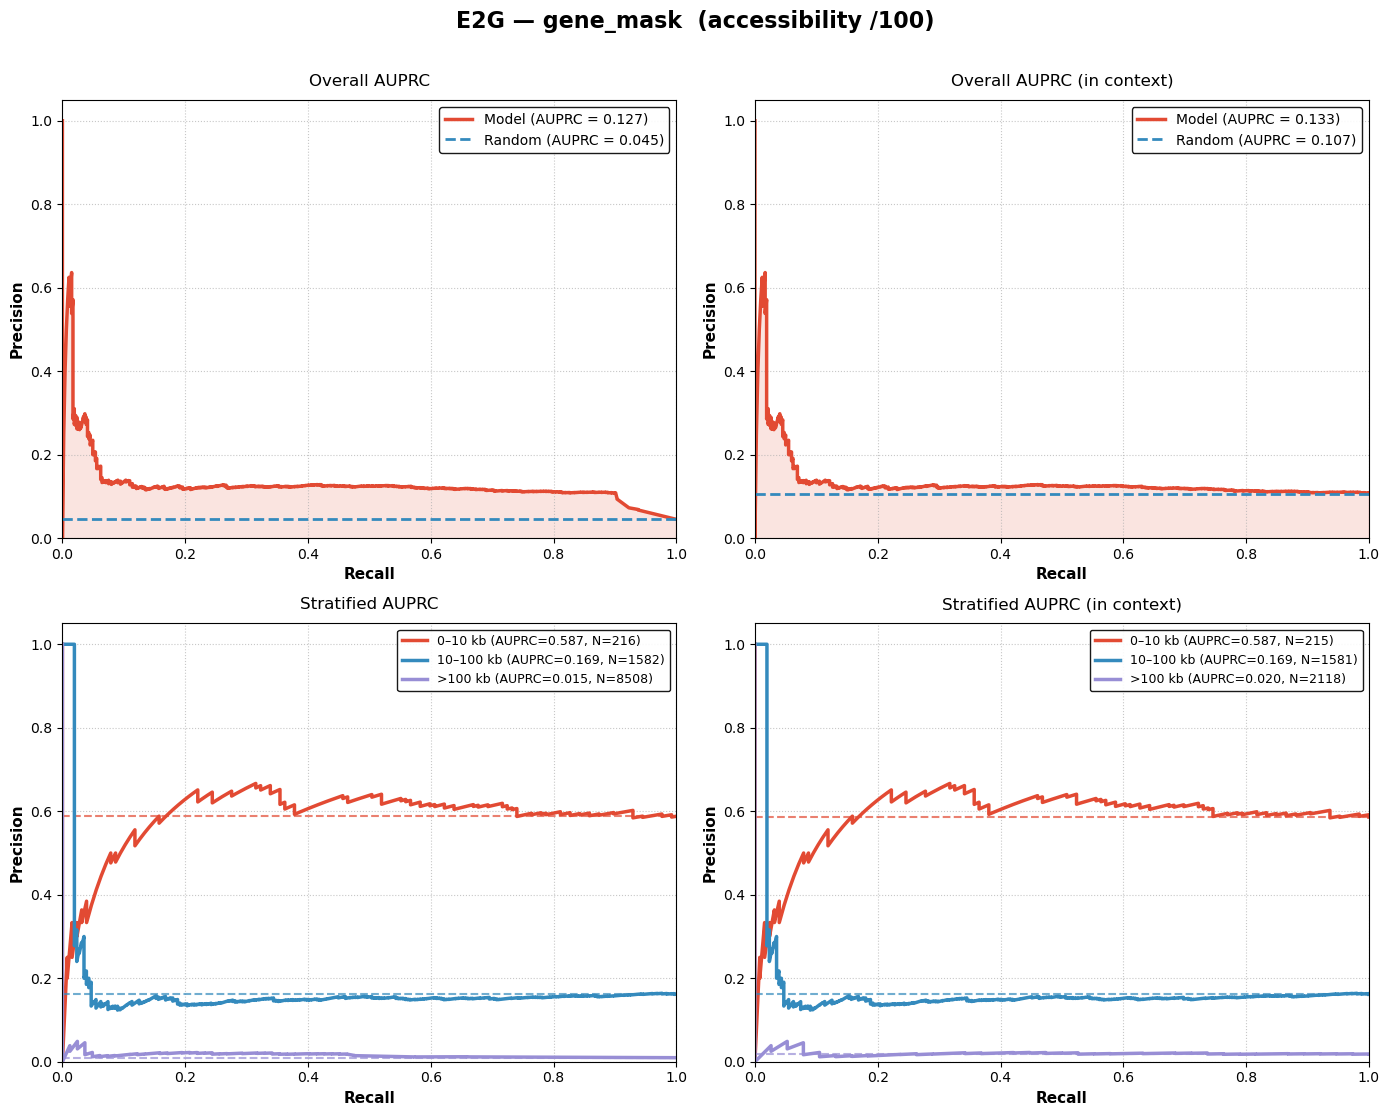

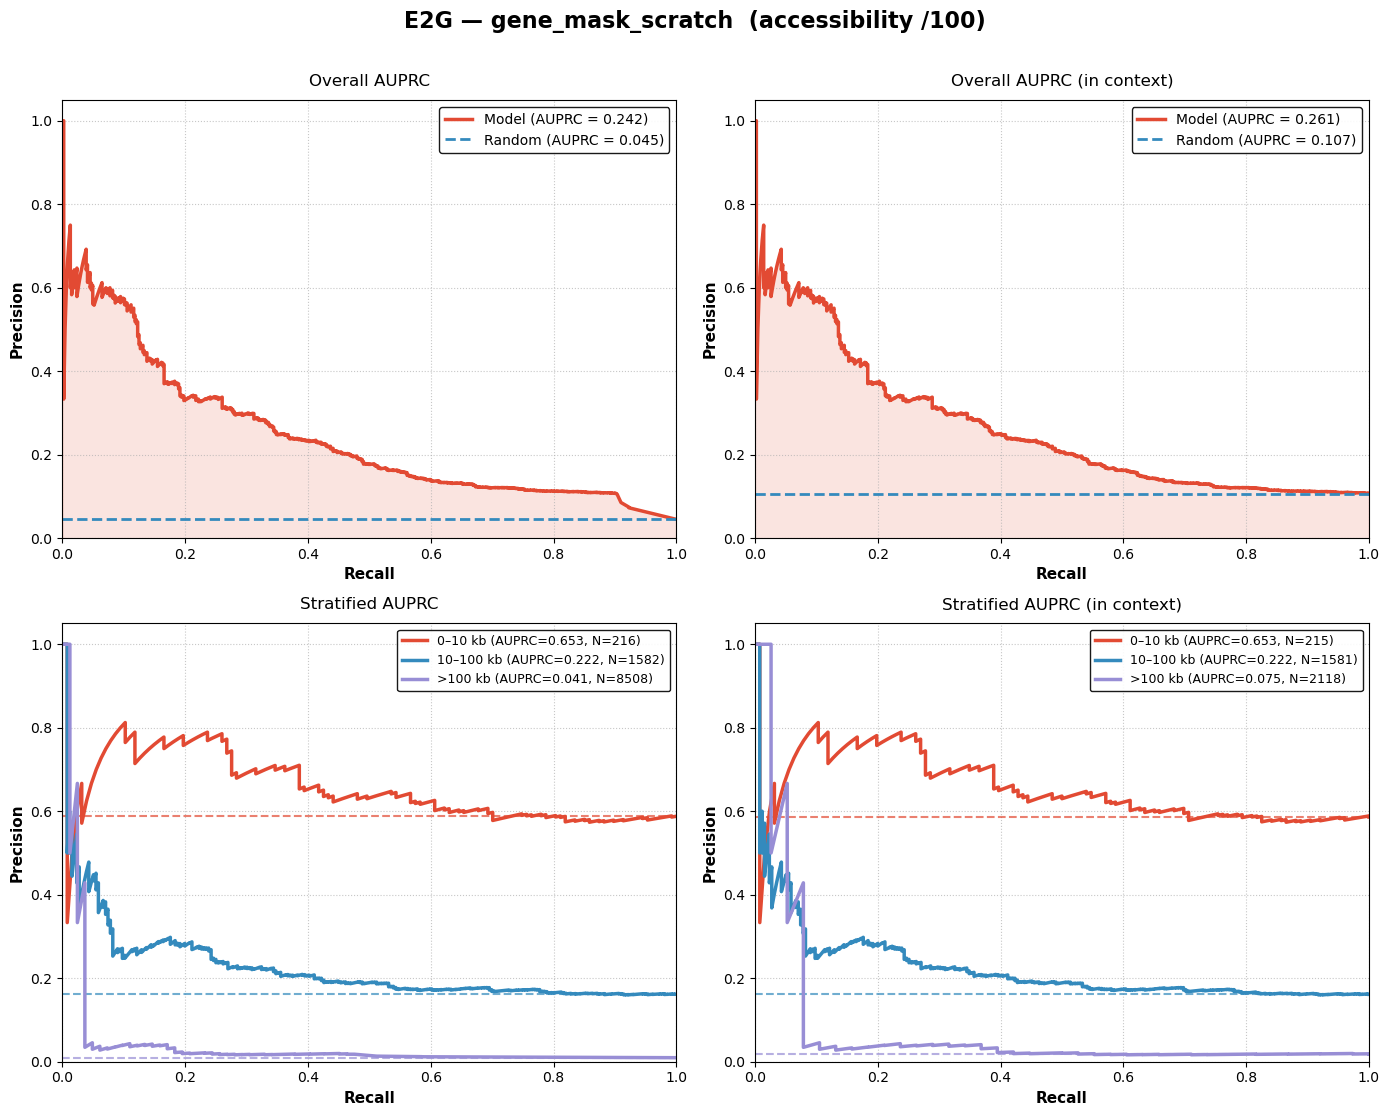

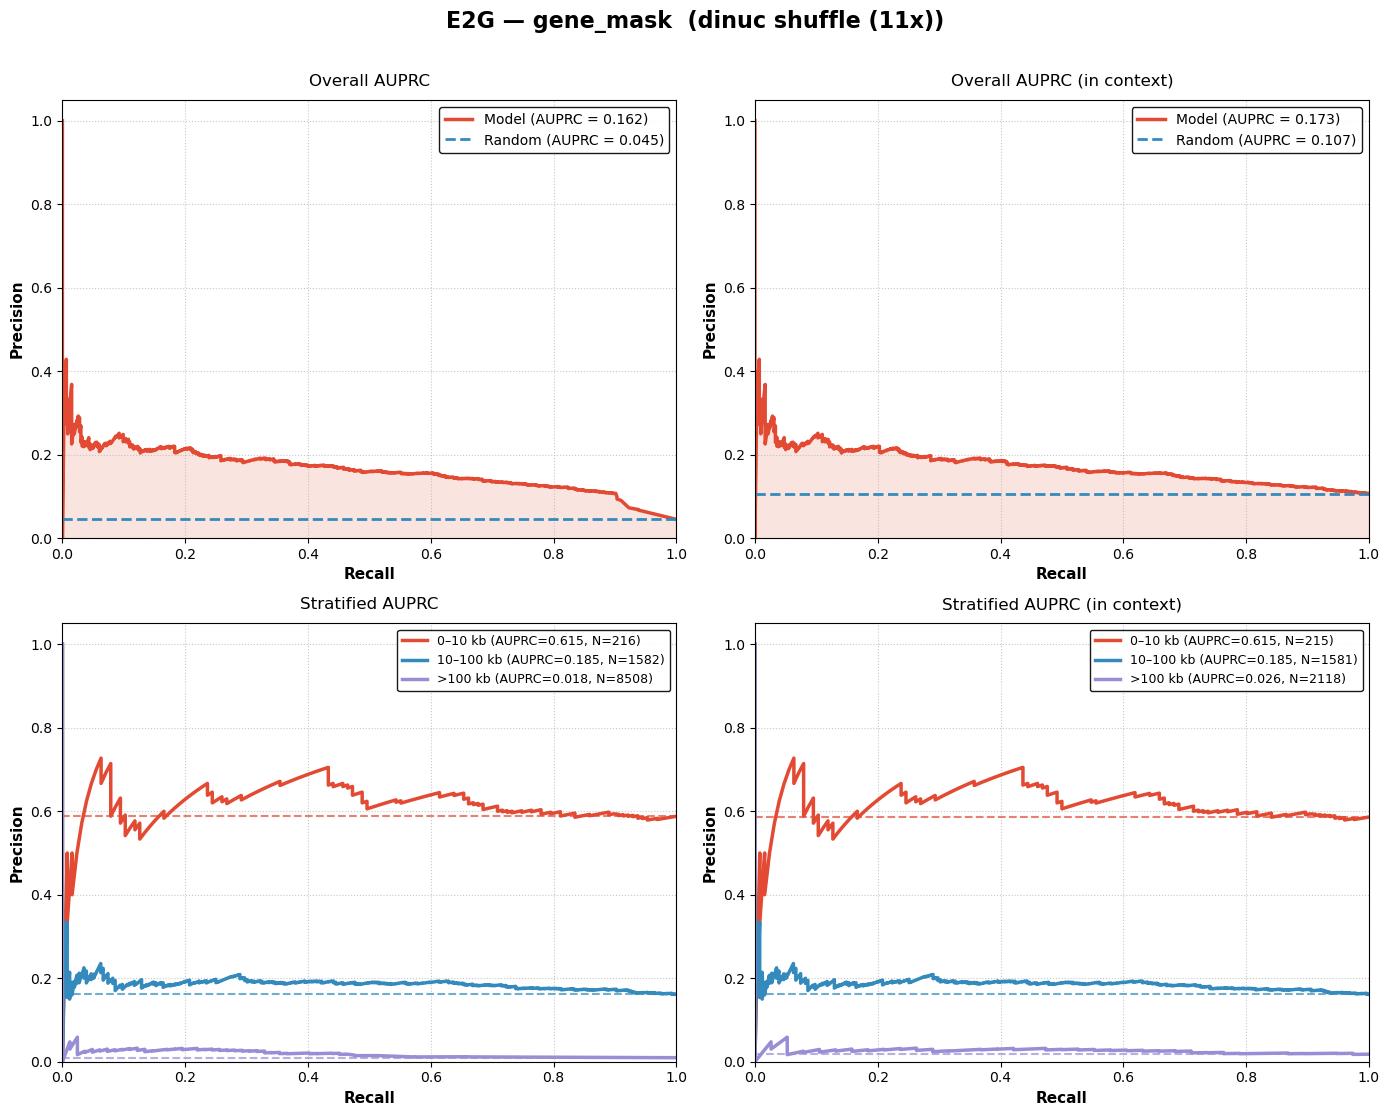

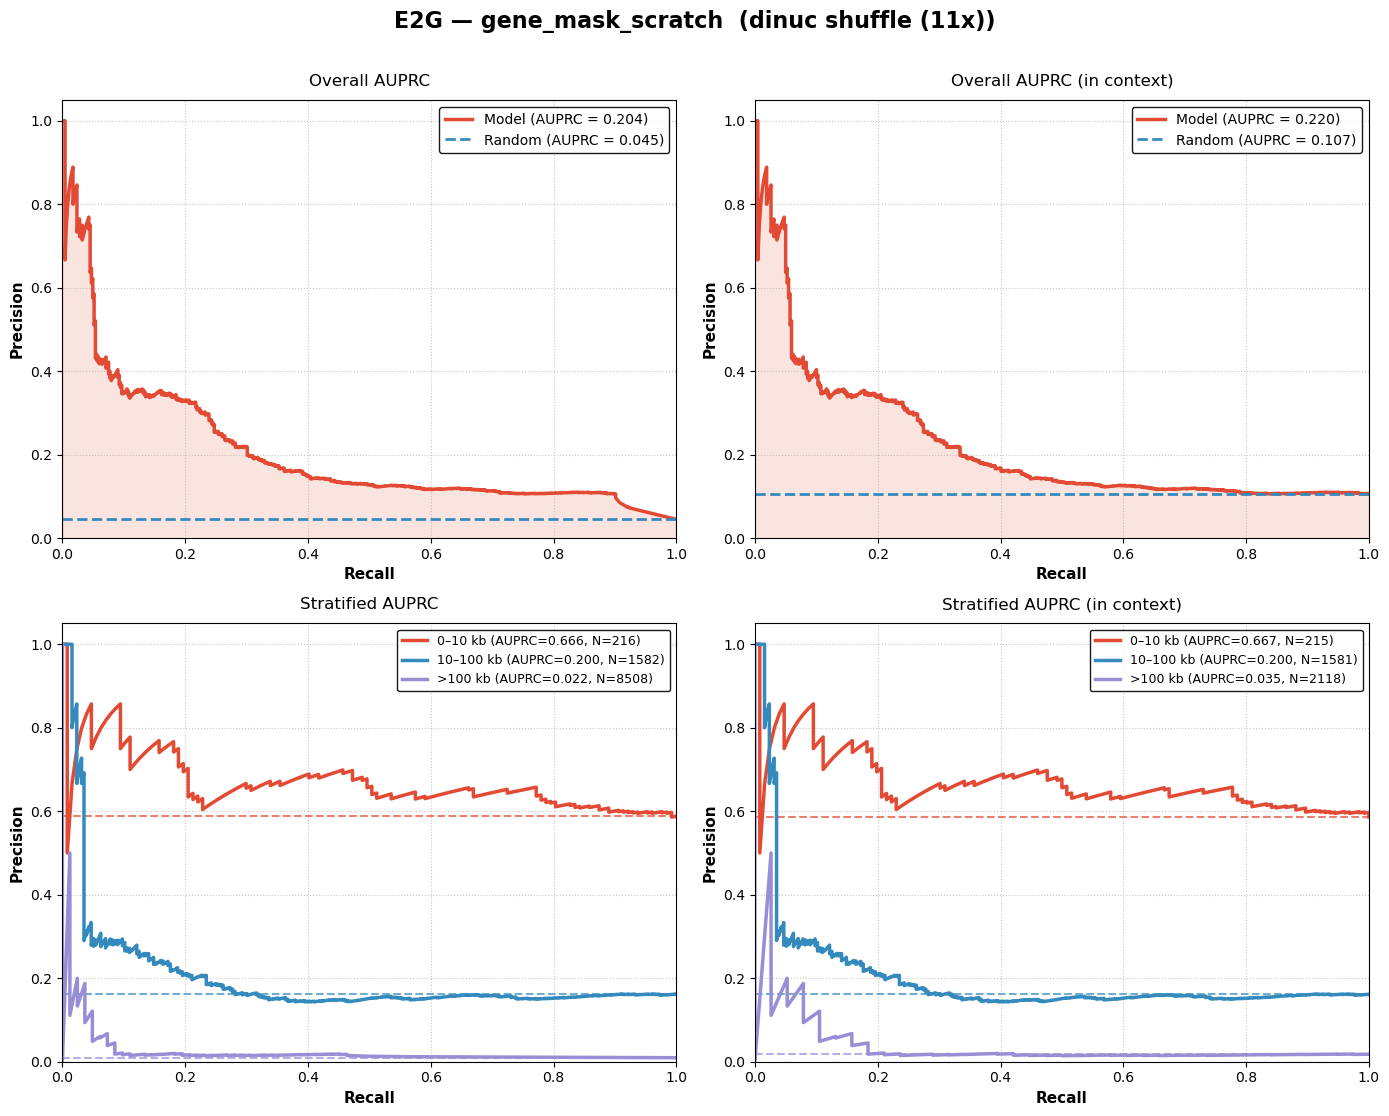

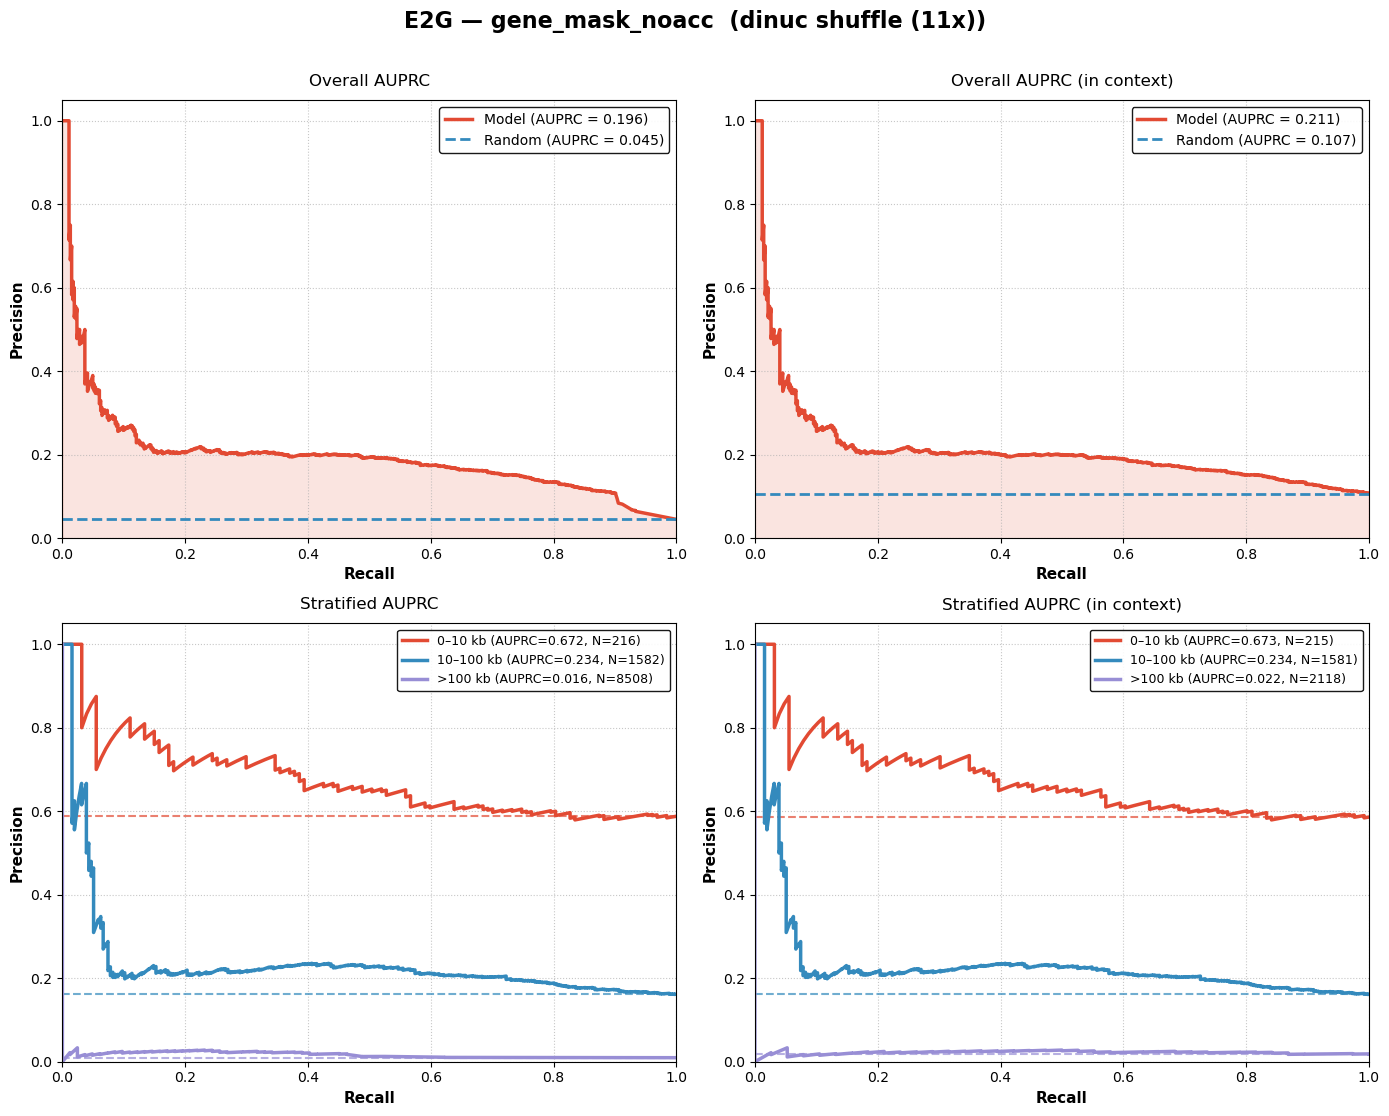

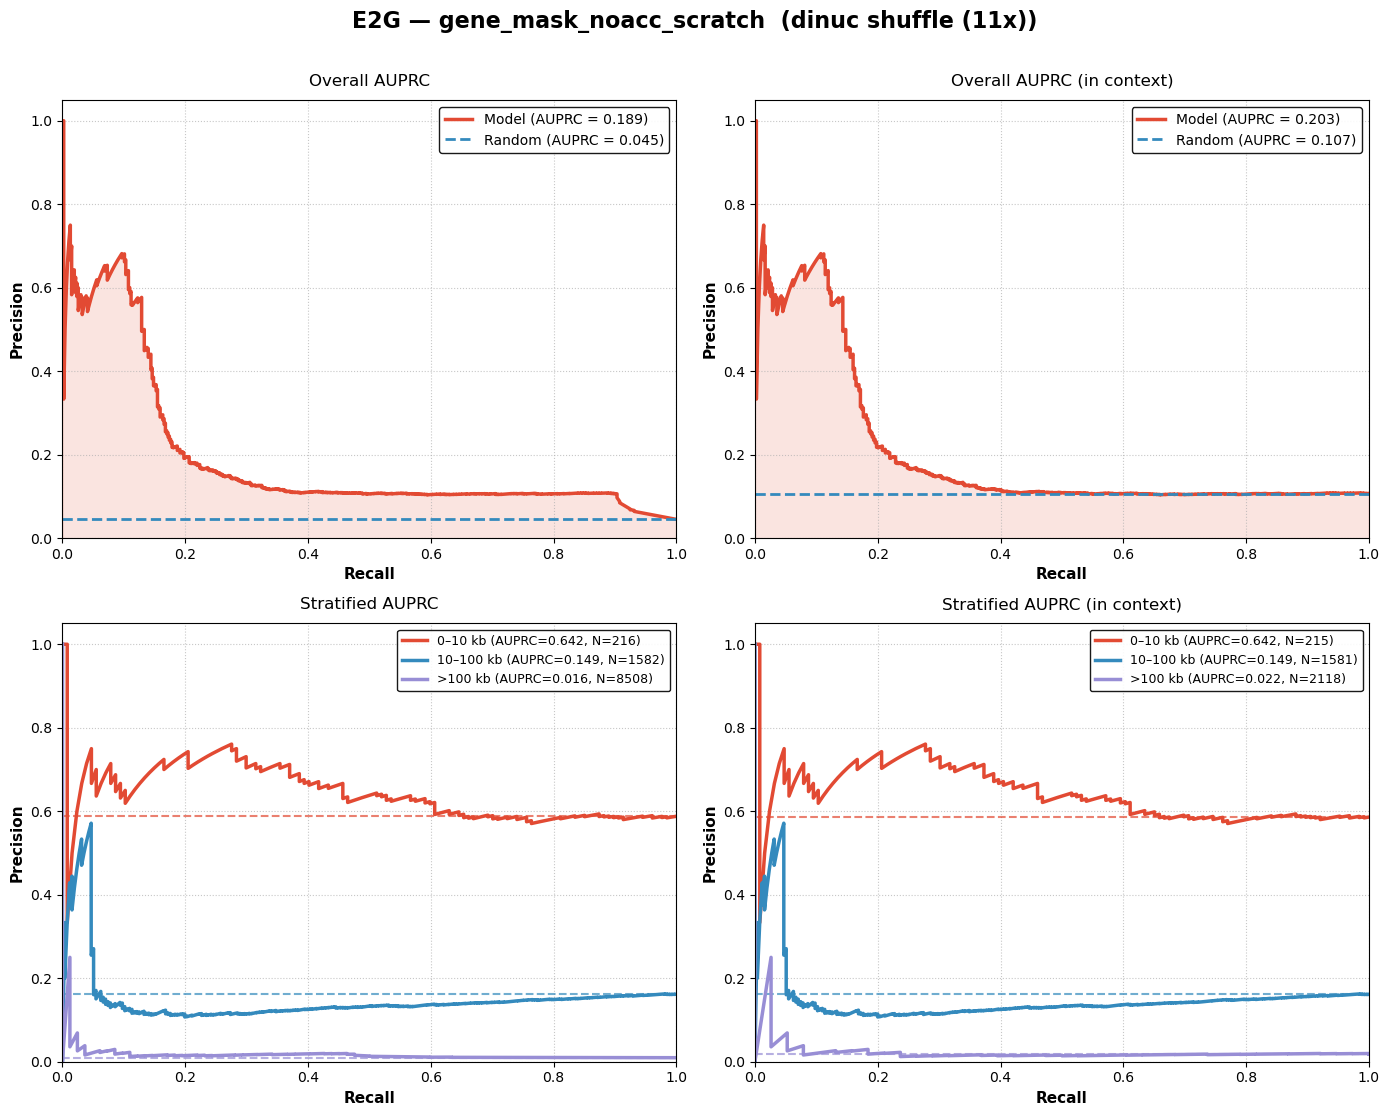

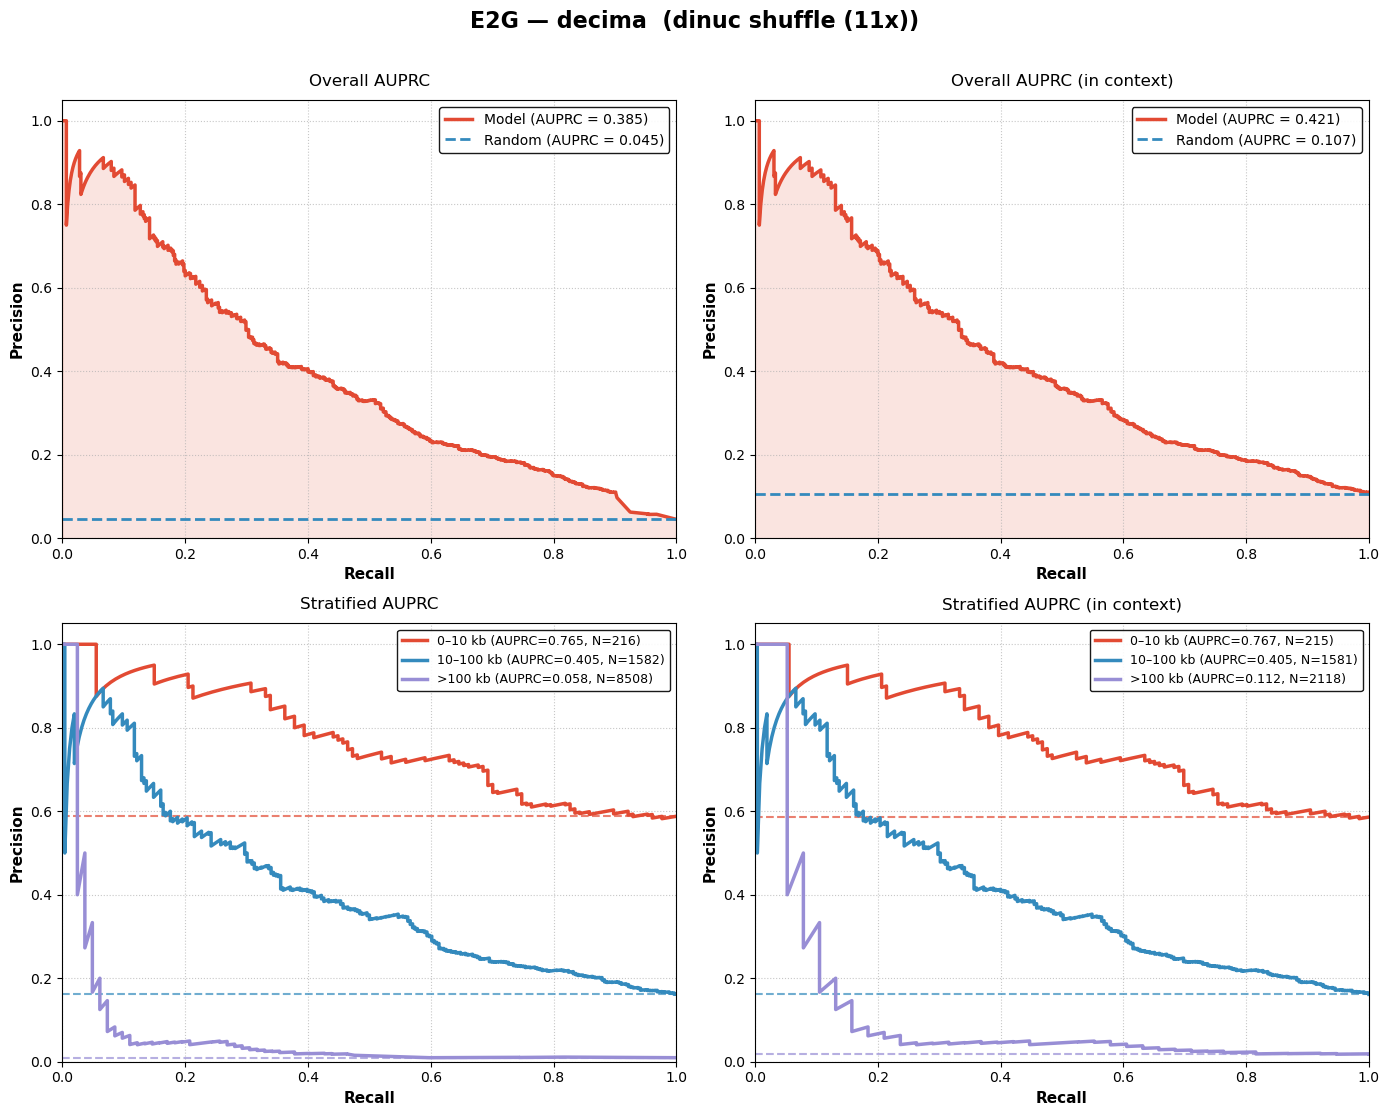

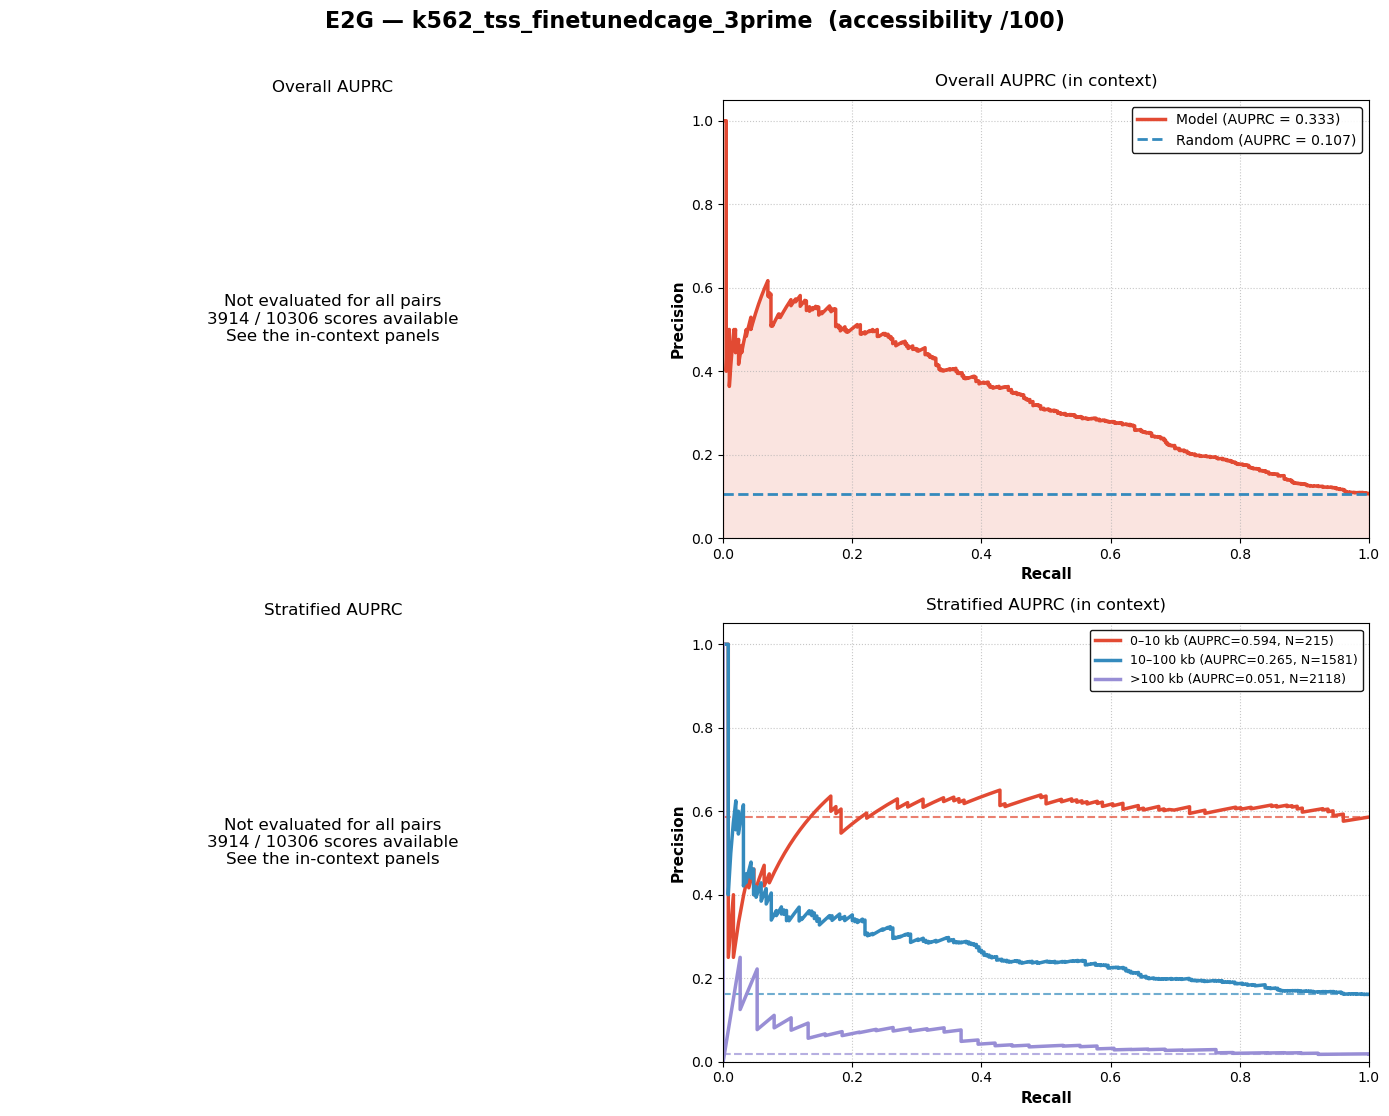

In [16]:
# One 2x2 per run. Every run sits on the same 10306 pairs and the same 3914 in-context mask, so
# In-context panels are matched within an arm; missing all-pair scores are marked explicitly.
for key in RUN_KEYS:
    d = e2g[key]
    plot_auprc_2x2(d["score"], d["in_context"], y_true, dist,
                   title=f"E2G — {key[0]}  ({ARM_LABEL[key[1]]})")


### 8a. Head-to-head, one panel per arm

The arms are kept in separate panels on purpose: `acc` divides the ATAC track by 100 and `shuffle`
scrambles 100 bp of sequence, and the two produce responses that differ by an order of magnitude
in raw log units (see the table in §8). Comparing a model in one arm against a model in the other
compares perturbations, not models.

`gene_mask` and `gene_mask_scratch` are drawn in **both** panels — solid in `acc`, dashed in
`shuffle` — so the two halves can be anchored against each other. The 3′ RNA fine-tune also uses real ATAC and joins the in-context `acc` panel.
Its all-pair curve is omitted because out-of-context links were not evaluated.


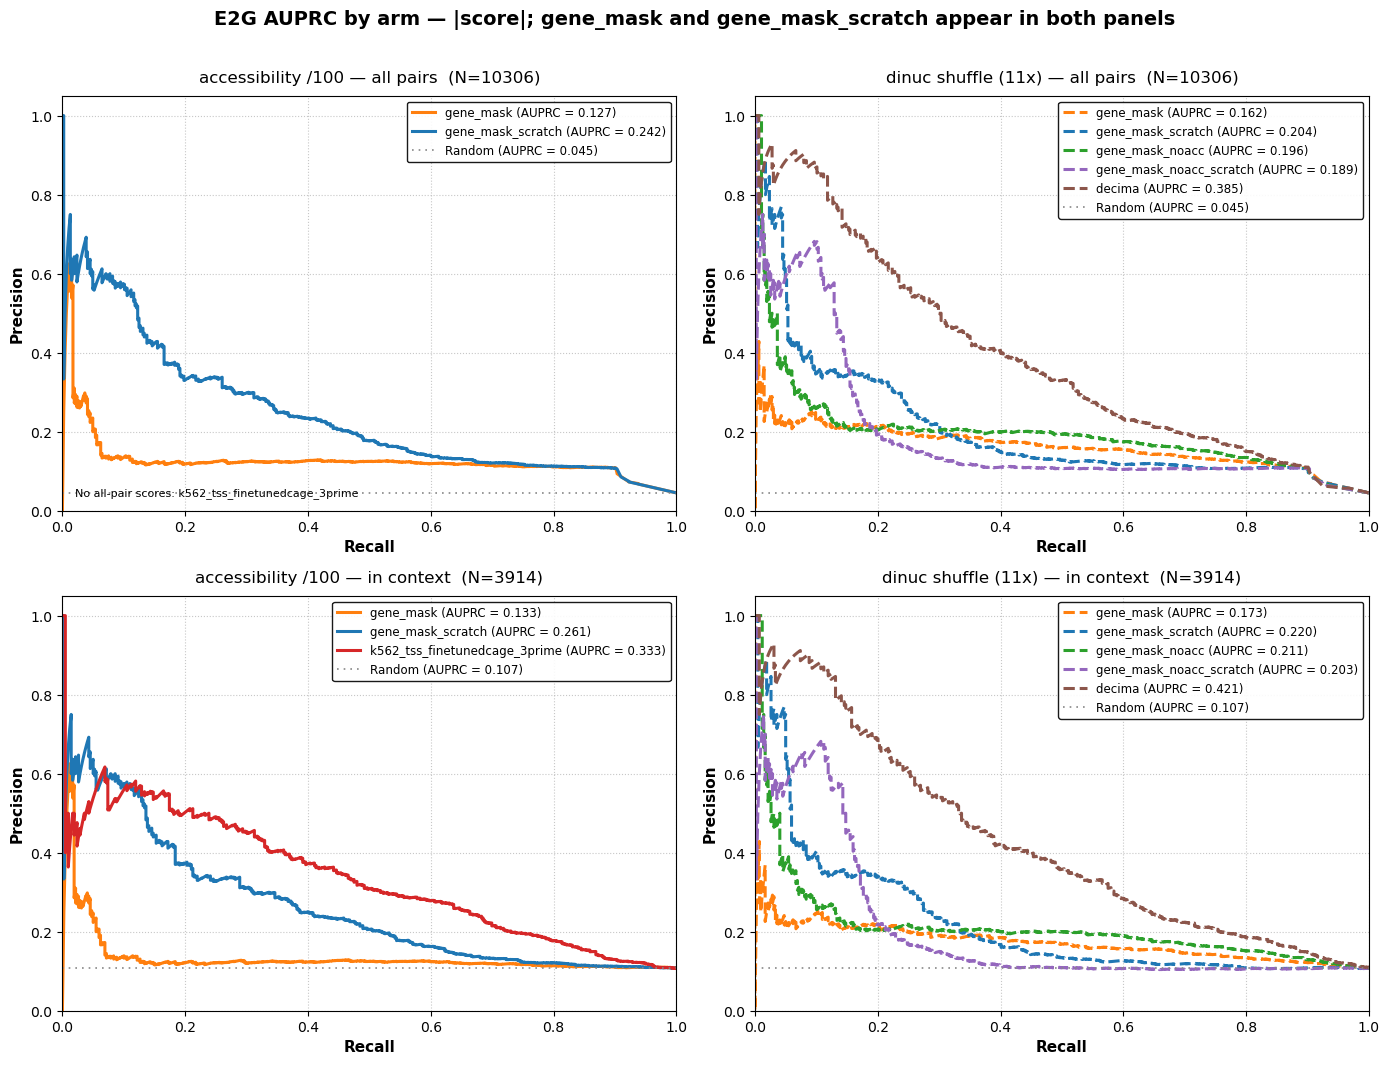

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10.5))
for col, arm in enumerate(ARMS):
    for row, (mask, subtitle) in enumerate([(np.ones(len(y_true), bool), "all pairs"),
                                            (ctx, "in context")]):
        ax = axes[row, col]
        yt = y_true[mask]
        unavailable = []
        for m in ARM_MODELS[arm]:
            d = e2g[(m, arm)]
            if not np.isfinite(d["score"][mask]).all():
                unavailable.append(m)
                continue
            prec, rec, _ = precision_recall_curve(yt, np.abs(d["score"][mask]))
            ax.plot(rec, prec, color=COLORS[m], lw=2.2, linestyle=ARM_LS[arm],
                    label=f"{m} (AUPRC = {auc(rec, prec):.3f})")
        if unavailable:
            ax.text(0.02, 0.03, "No all-pair scores: " + ", ".join(unavailable),
                    transform=ax.transAxes, fontsize=8, va="bottom")
        ax.axhline(yt.mean(), color="#888", lw=1.2, linestyle=(0, (1, 3)),
                   label=f"Random (AUPRC = {yt.mean():.3f})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Recall", fontsize=11, fontweight="bold")
        ax.set_ylabel("Precision", fontsize=11, fontweight="bold")
        ax.set_title(f"{ARM_LABEL[arm]} — {subtitle}  (N={int(mask.sum())})", fontsize=12, pad=10)
        ax.grid(True, linestyle=":", alpha=0.7)
        ax.legend(loc="upper right", fontsize=8.5, framealpha=0.9, edgecolor="black")

fig.suptitle("E2G AUPRC by arm — |score|; gene_mask and gene_mask_scratch appear in both panels",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


### 8a-bis. The shuffle-arm 2x2

The newest run (`k562_tss_sc_decima_scratch_ep27_dinuc`) fills the last cell of the
**pretraining × accessibility-input** grid inside the `shuffle` arm, so for the first time all four
cells are scored under one identical perturbation — element ± 100 bp, dinucleotide-shuffled 11
times, seed 0. This is the same 2x2 as §1, now on AUPRC instead of expression metrics.

Bars rather than a heatmap, so the random baseline sits on the same axis; `decima` is off-grid and
left out. **Caveat 1 still applies** — the four cells are at epochs 16 / 27 / 04 / 19, so a main
effect here is confounded with training length, and §8c decides how much of any of it to believe.


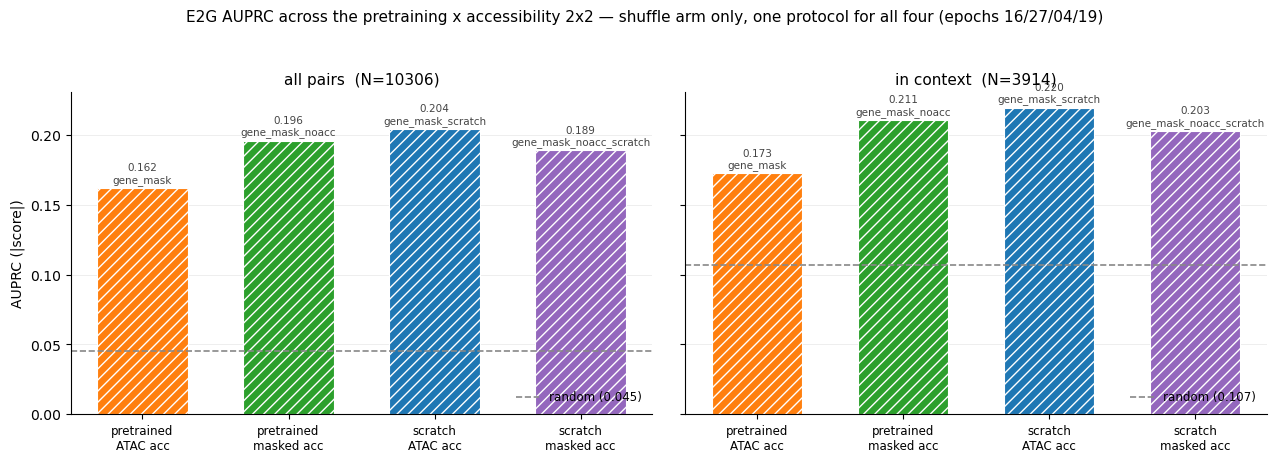

main effects on AUPRC, all pairs (positive = the first term is better):
  pretrained - scratch, ATAC     accessibility : -0.0422
  pretrained - scratch, masked   accessibility : +0.0070
  ATAC - masked,        pretrained init        : -0.0340
  ATAC - masked,        scratch    init        : +0.0152

main effects on AUPRC, in context (positive = the first term is better):
  pretrained - scratch, ATAC     accessibility : -0.0470
  pretrained - scratch, masked   accessibility : +0.0078
  ATAC - masked,        pretrained init        : -0.0381
  ATAC - masked,        scratch    init        : +0.0166



In [18]:
# The 2x2 read inside the shuffle arm alone -- one perturbation, four cells, so the two main
# effects are separable here in a way they are not across arms.
SHUF_CELL = {("pretrained", "ATAC"): "gene_mask", ("scratch", "ATAC"): "gene_mask_scratch",
             ("pretrained", "masked"): "gene_mask_noacc",
             ("scratch", "masked"): "gene_mask_noacc_scratch"}
inits, accs = ["pretrained", "scratch"], ["ATAC", "masked"]
grid_keys = [(SHUF_CELL[(i, a)], "shuffle") for i in inits for a in accs]

auprc_2x2 = {}
for subset, mask in [("all pairs", np.ones(len(y_true), bool)), ("in context", ctx)]:
    yt = y_true[mask]
    for key in grid_keys:
        prec, rec, _ = precision_recall_curve(yt, np.abs(e2g[key]["score"][mask]))
        auprc_2x2[(subset, key[0])] = auc(rec, prec)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
x = np.arange(len(grid_keys))
labels = [f"{i}\n{a} acc" for i in inits for a in accs]
for ax, subset in zip(axes, ["all pairs", "in context"]):
    mask = np.ones(len(y_true), bool) if subset == "all pairs" else ctx
    vals = [auprc_2x2[(subset, k[0])] for k in grid_keys]
    ax.bar(x, vals, 0.62, color=[COLORS[k[0]] for k in grid_keys],
           hatch="///", edgecolor="white", linewidth=0.8)
    for xi, v, k in zip(x, vals, grid_keys):
        ax.text(xi, v + 0.002, f"{v:.3f}\n{k[0]}", ha="center", va="bottom", fontsize=7.5,
                color="#444")
    ax.axhline(y_true[mask].mean(), color="#888", linestyle="--", lw=1.2,
               label=f"random ({y_true[mask].mean():.3f})")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8.5)
    ax.set_title(f"{subset}  (N={int(mask.sum())})", fontsize=11)
    ax.legend(frameon=False, fontsize=8.5, loc="lower right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)

axes[0].set_ylabel("AUPRC (|score|)")
fig.suptitle("E2G AUPRC across the pretraining x accessibility 2x2 — shuffle arm only, one "
             "protocol for all four (epochs 16/27/04/19)", fontsize=11, y=1.04)
plt.tight_layout()
plt.show()

# the two main effects, read off the grid rather than eyeballed -- same form as the expression 2x2
for subset in ["all pairs", "in context"]:
    print(f"main effects on AUPRC, {subset} (positive = the first term is better):")
    for a in accs:
        d = (auprc_2x2[(subset, SHUF_CELL[("pretrained", a)])]
             - auprc_2x2[(subset, SHUF_CELL[("scratch", a)])])
        print(f"  pretrained - scratch, {a:8s} accessibility : {d:+.4f}")
    for i in inits:
        d = (auprc_2x2[(subset, SHUF_CELL[(i, "ATAC")])]
             - auprc_2x2[(subset, SHUF_CELL[(i, "masked")])])
        print(f"  ATAC - masked,        {i:10s} init        : {d:+.4f}")
    print()


### 8b. Score direction

Knocking out an enhancer should *lower* predicted expression, so `-score` ought to be the
discriminative direction. `|score|` winning means the model responds to the perturbation without a
consistent sign, and `+score` winning means it is outright inverted. Two things are worth reading
separately: the **offset** (mean in-context score, % negative, printed in §8) and the **ranking**
(which variant maximizes AUPRC) — a model can be badly offset and still rank correctly.


,model,arm,subset,N,baseline,n_scored,status,|score|,-score,+score,eff_r,|z|
0,gene_mask,acc,all,10306,0.0451,10306,evaluated,0.1266,0.1424,0.0819,0.0046,NaN
1,gene_mask,acc,in context,3914,0.1071,3914,evaluated,0.1334,0.2069,0.1050,-0.0421,NaN
2,gene_mask_scratch,acc,all,10306,0.0451,10306,evaluated,0.2417,0.1336,0.1568,-0.0083,NaN
3,gene_mask_scratch,acc,in context,3914,0.1071,3914,evaluated,0.2611,0.1874,0.1889,-0.0089,NaN
4,gene_mask,shuffle,all,10306,0.0451,10306,evaluated,0.1620,0.1471,0.0707,-0.0471,0.0809
5,gene_mask,shuffle,in context,3914,0.1071,3914,evaluated,0.1726,0.1835,0.1067,-0.0587,0.1087
6,gene_mask_scratch,shuffle,all,10306,0.0451,10306,evaluated,0.2042,0.1161,0.1281,0.0474,0.0856
7,gene_mask_scratch,shuffle,in context,3914,0.1071,3914,evaluated,0.2195,0.1571,0.1661,0.0577,0.1068
8,gene_mask_noacc,shuffle,all,10306,0.0451,10306,evaluated,0.1960,0.1962,0.0763,-0.1863,0.0996
9,gene_mask_noacc,shuffle,in context,3914,0.1071,3914,evaluated,0.2107,0.2399,0.1095,-0.2128,0.1166


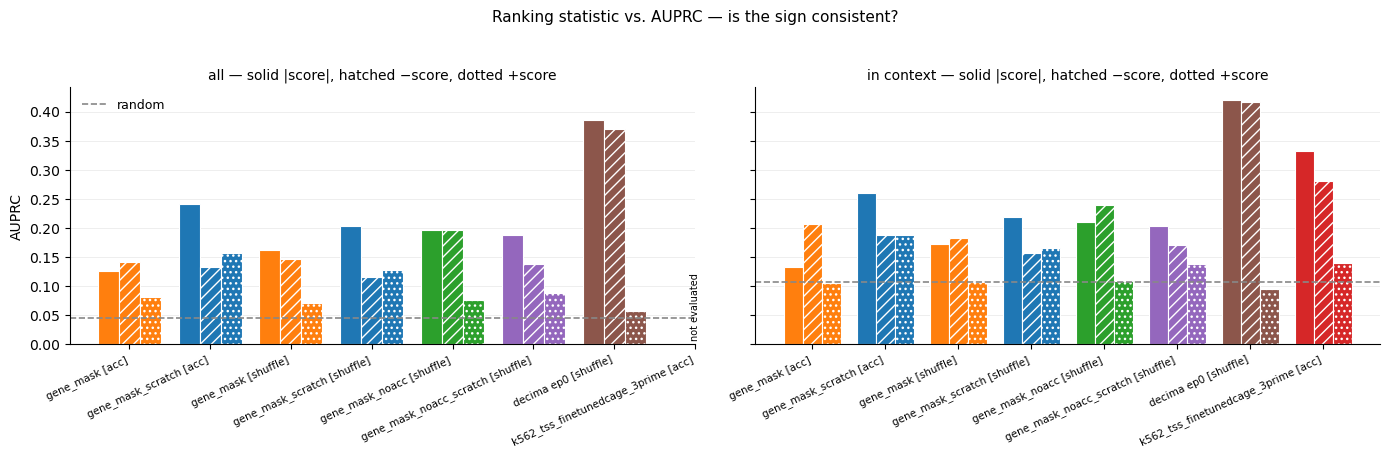

In [19]:
from scipy import stats

variants = {"|score|": np.abs, "-score": lambda s: -s, "+score": lambda s: s}
rows = []
for key in RUN_KEYS:
    d = e2g[key]
    for subset, mask in [("all", np.ones(len(y_true), bool)), ("in context", ctx)]:
        yt = y_true[mask]
        entry = {"model": key[0], "arm": key[1], "subset": subset, "N": int(mask.sum()),
                 "baseline": yt.mean(), "n_scored": int(np.isfinite(d["score"][mask]).sum())}
        if entry["n_scored"] != entry["N"]:
            entry.update({vname: np.nan for vname in variants})
            entry.update({"eff_r": np.nan, "status": "not evaluated for all pairs"})
            rows.append(entry)
            continue
        entry["status"] = "evaluated"
        for vname, fn in variants.items():
            prec, rec, _ = precision_recall_curve(yt, fn(d["score"][mask]))
            entry[vname] = auc(rec, prec)
        if d["sd"] is not None:
            # |z| = |score| / that element's own across-shuffle std. Only definable because
            # --save_all_shuffles kept the individual shuffles; asks whether the shift is large FOR
            # THAT ELEMENT rather than large in absolute log units.
            z = np.divide(d["score"], d["sd"], out=np.zeros_like(d["score"]), where=d["sd"] > 0)
            prec, rec, _ = precision_recall_curve(yt, np.abs(z[mask]))
            entry["|z|"] = auc(rec, prec)
        # sign convention: -score is "predicted to be repressed", and every Regulated pair has a
        # negative EffectSize, so a model with the right direction gives a negative r here
        entry["eff_r"] = stats.pearsonr(-d["score"][mask], effect[mask])[0]
        rows.append(entry)
sign_df = pd.DataFrame(rows)
display(sign_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
x = np.arange(len(RUN_KEYS))
w = 0.26
for ax, subset in zip(axes, ["all", "in context"]):
    sub = sign_df[sign_df["subset"] == subset].set_index(["model", "arm"])
    for i, (vname, hatch) in enumerate(zip(variants, [None, "///", "..."])):
        ax.bar(x + (i - 1) * w, [sub.loc[k, vname] for k in RUN_KEYS], w,
               color=[COLORS[k[0]] for k in RUN_KEYS], hatch=hatch, edgecolor="white",
               linewidth=0.8)
    for j, key in enumerate(RUN_KEYS):
        if pd.isna(sub.loc[key, "|score|"]):
            ax.text(j, 0.01, "not evaluated", rotation=90, ha="center", fontsize=7)
    ax.axhline(sub["baseline"].mean(), color="#888", linestyle="--", lw=1.2, label="random")
    ax.set_xticks(x)
    ax.set_xticklabels([run_label(k) for k in RUN_KEYS], rotation=25, ha="right", fontsize=7.5)
    ax.set_title(f"{subset} — solid |score|, hatched −score, dotted +score", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6)
    ax.set_axisbelow(True)

axes[0].set_ylabel("AUPRC")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Ranking statistic vs. AUPRC — is the sign consistent?", fontsize=11, y=1.03)
plt.tight_layout()
plt.show()


### 8c. Does the shuffle response clear its own noise floor?

This check only exists for the `shuffle` arm, and it decides how much of §8a to believe for the
four models in it. Each element was shuffled 11 independent times, so each element carries its
own std — the scale on which its prediction wobbles when you scramble 100 bp of sequence for no
particular reason. A response that does not clear that std is not a measurement of anything.

Left panel plots `log10(|score| / sd)` per element, with the dashed line at `|score| = 1 sd`. A
violin centred on the line means the arm is measuring shuffle noise. Right panel asks whether
normalizing by the noise floor (`|z|`) actually helps the ranking, or whether it just divides
signal and noise by the same thing.

The `acc` arm cannot be checked this way — one perturbed value per element, so there is no
internal scale to judge it against. That asymmetry is worth keeping in mind when reading §8a: the
shuffle models' numbers come with a noise audit attached and the `acc` models' do not.


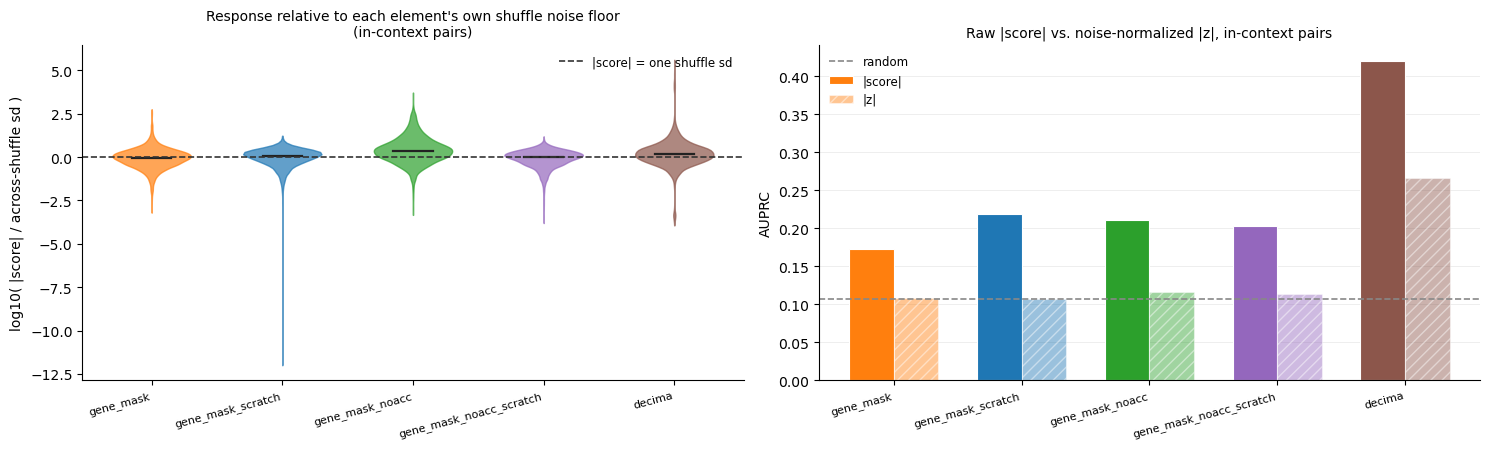

run                                     median |score|/sd  % of elements >2 sd   % >3 sd   (in context)
gene_mask [shuffle]                                  0.94               24.3%     14.2%
gene_mask_scratch [shuffle]                          1.18               27.0%     11.9%
gene_mask_noacc [shuffle]                            2.34               54.1%     42.8%
gene_mask_noacc_scratch [shuffle]                    0.98               20.1%      7.8%
decima ep0 [shuffle]                                 1.51               41.4%     29.3%


In [20]:
SHUF_KEYS = [k for k in RUN_KEYS if k[1] == "shuffle"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

ax = axes[0]
data, positions, face = [], [], []
for i, key in enumerate(SHUF_KEYS):
    d = e2g[key]
    m = d["in_context"] & (d["sd"] > 0)
    data.append(np.log10(np.abs(d["score"][m]) / d["sd"][m] + 1e-12))
    positions.append(i)
    face.append(COLORS[key[0]])
parts = ax.violinplot(data, positions=positions, widths=0.6, showextrema=False)
for body, fc in zip(parts["bodies"], face):
    body.set_facecolor(fc)
    body.set_edgecolor(fc)
    body.set_alpha(0.7)
for pos, arr in zip(positions, data):
    ax.plot([pos - 0.15, pos + 0.15], [np.median(arr)] * 2, color="#222", lw=1.6)
ax.axhline(0, color="#333", linestyle="--", lw=1.2, label="|score| = one shuffle sd")
ax.set_xticks(positions)
ax.set_xticklabels([k[0] for k in SHUF_KEYS], rotation=15, ha="right", fontsize=8)
ax.set_ylabel("log10( |score| / across-shuffle sd )")
ax.set_title("Response relative to each element's own shuffle noise floor\n(in-context pairs)",
             fontsize=10)
ax.legend(frameon=False, fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
sub = sign_df[sign_df["subset"] == "in context"].set_index(["model", "arm"])
x = np.arange(len(SHUF_KEYS))
w = 0.35
for i, (stat, hatch, alpha) in enumerate([("|score|", None, 1.0), ("|z|", "///", 0.45)]):
    ax.bar(x + (i - 0.5) * w, [sub.loc[k, stat] for k in SHUF_KEYS], w,
           color=[COLORS[k[0]] for k in SHUF_KEYS], alpha=alpha, hatch=hatch,
           edgecolor="white", linewidth=0.8, label=stat)
ax.axhline(sub["baseline"].mean(), color="#888", linestyle="--", lw=1.2, label="random")
ax.set_xticks(x)
ax.set_xticklabels([k[0] for k in SHUF_KEYS], rotation=15, ha="right", fontsize=8)
ax.set_ylabel("AUPRC")
ax.set_title("Raw |score| vs. noise-normalized |z|, in-context pairs", fontsize=10)
ax.legend(frameon=False, fontsize=8.5)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print(f"{'run':38s}{'median |score|/sd':>19s}{'% of elements >2 sd':>21s}{'% >3 sd':>10s}"
      f"   (in context)")
for key in SHUF_KEYS:
    d = e2g[key]
    m = d["in_context"] & (d["sd"] > 0)
    ratio = np.abs(d["score"][m]) / d["sd"][m]
    print(f"{run_label(key):38s}{np.median(ratio):19.2f}{np.mean(ratio > 2):20.1%}"
          f"{np.mean(ratio > 3):10.1%}")


### 8d. Model score vs. CRISPRi effect size

The plotted score is `-score`, so positive means "predicted to be repressed by the perturbation".
Every `Regulated` pair in the benchmark has a *negative* `EffectSize`, so a model that gets the
direction right produces a **negative** `r` here; a positive `r` means it moves the wrong way.

x-axis units are natural-log differences in every panel, but the two arms differ in magnitude by
roughly an order of magnitude, so the panels are not overlayable across arms — `r` is scale-free
and is the comparable quantity.


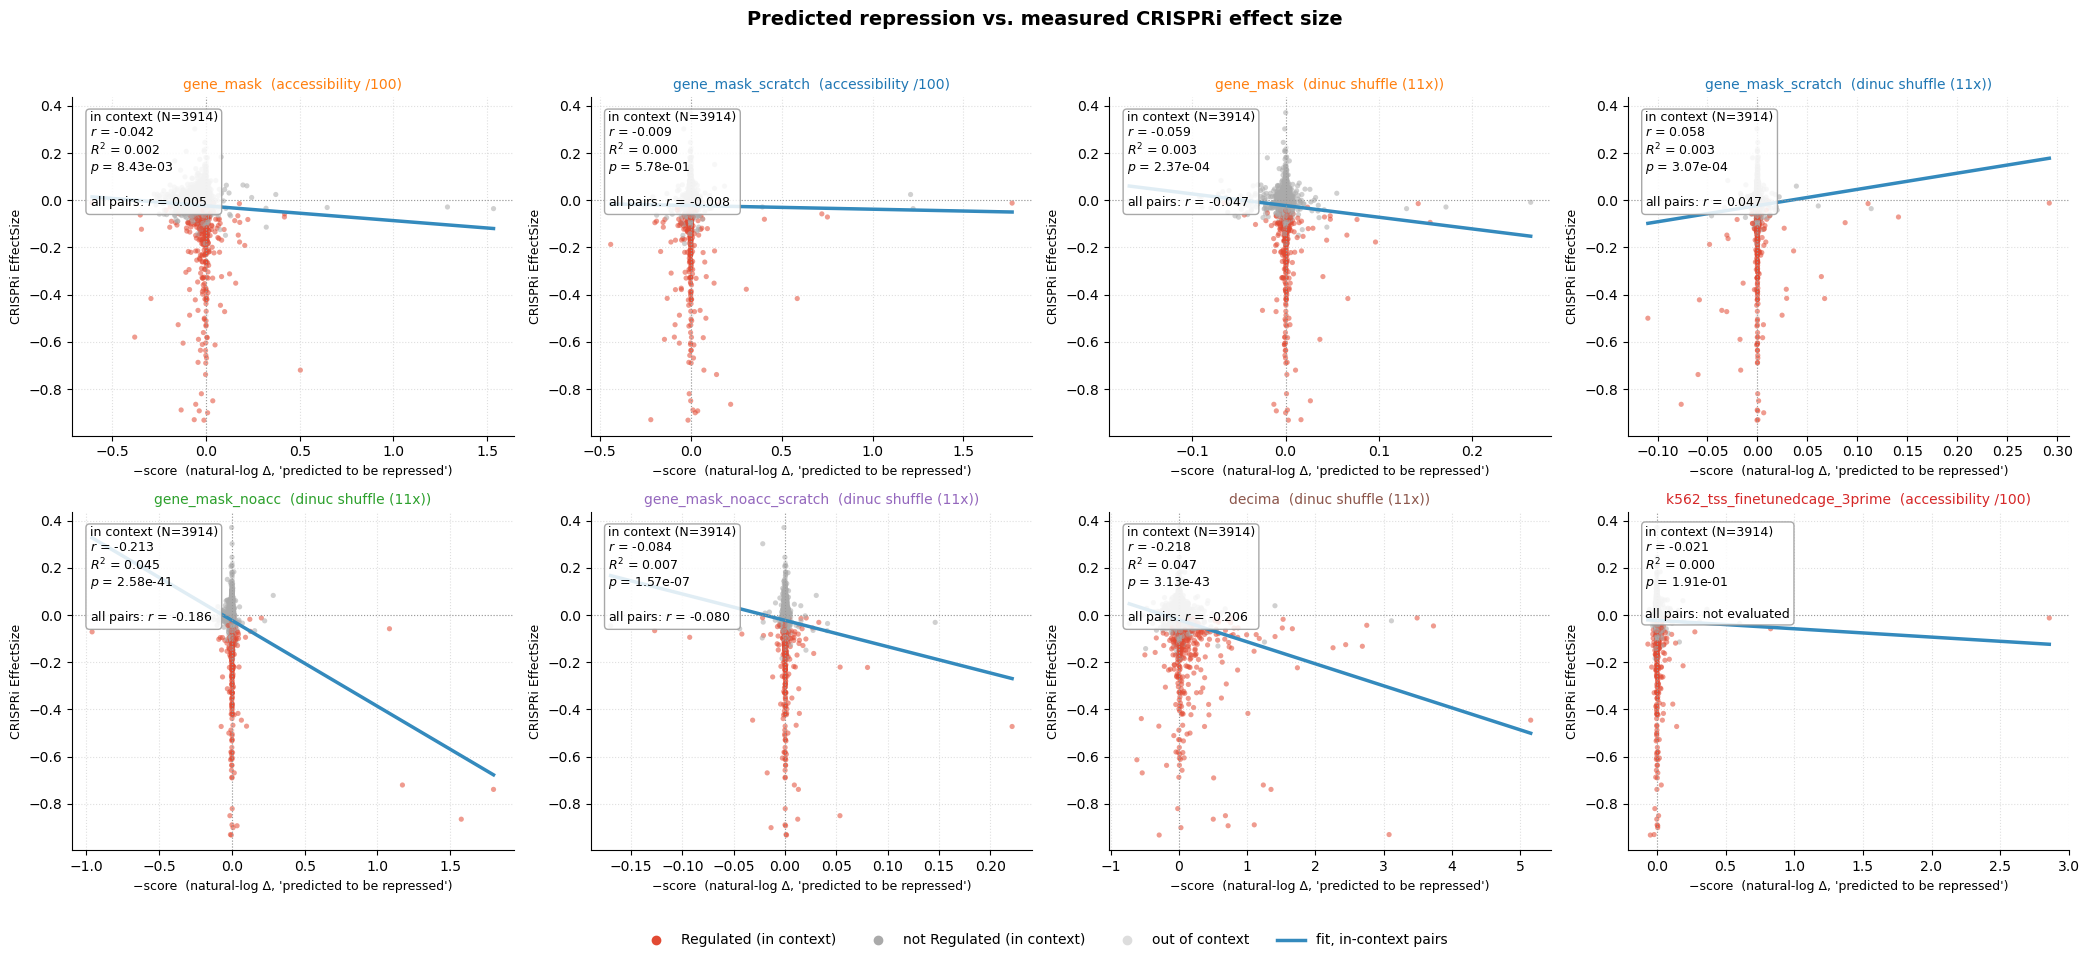

In [21]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 4, figsize=(21, 9.5))
flat = axes.ravel()

for ax, key in zip(flat, RUN_KEYS):
    d = e2g[key]
    model_score = -d["score"]
    ic = d["in_context"]

    ax.scatter(model_score[~ic], effect[~ic], c="#dddddd", alpha=0.4, s=10,
               linewidths=0, rasterized=True)
    colors = np.where(y_true.astype(bool), "#E24A33", "#aaaaaa")
    ax.scatter(model_score[ic], effect[ic], c=colors[ic], alpha=0.55, s=14,
               linewidths=0, rasterized=True)

    # Fit only in-context pairs. Legacy out-of-context scores are ~0; new ones are NaN.
    slope, intercept, r_ctx, p_ctx, _ = stats.linregress(model_score[ic], effect[ic])
    xs = np.linspace(model_score[ic].min(), model_score[ic].max(), 200)
    ax.plot(xs, intercept + slope * xs, color="#348ABD", lw=2.5)

    all_text = (f"all pairs: $r$ = {stats.pearsonr(model_score, effect)[0]:.3f}"
                if np.isfinite(model_score).all() else "all pairs: not evaluated")
    p_str = f"{p_ctx:.2e}" if p_ctx > 1e-300 else "< 1e-300"
    textstr = (f"in context (N={int(ic.sum())})\n$r$ = {r_ctx:.3f}\n$R^2$ = {r_ctx**2:.3f}\n"
               f"$p$ = {p_str}\n\n{all_text}")
    ax.text(0.04, 0.96, textstr, transform=ax.transAxes, fontsize=9, verticalalignment="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="#999"))

    ax.axhline(0, color="#999", lw=0.8, linestyle=":")
    ax.axvline(0, color="#999", lw=0.8, linestyle=":")
    ax.set_xlabel("−score  (natural-log Δ, 'predicted to be repressed')", fontsize=9)
    ax.set_ylabel("CRISPRi EffectSize", fontsize=9)
    ax.set_title(f"{key[0]}  ({ARM_LABEL[key[1]]})", fontsize=10, color=COLORS[key[0]])
    ax.grid(True, linestyle=":", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

for ax in flat[len(RUN_KEYS):]:
    ax.set_visible(False)
handles = [Line2D([], [], marker="o", ls="", color="#E24A33", label="Regulated (in context)"),
           Line2D([], [], marker="o", ls="", color="#aaaaaa", label="not Regulated (in context)"),
           Line2D([], [], marker="o", ls="", color="#dddddd", label="out of context"),
           Line2D([], [], color="#348ABD", lw=2.5, label="fit, in-context pairs")]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.0), frameon=False,
           fontsize=10, ncol=4)
fig.suptitle("Predicted repression vs. measured CRISPRi effect size", fontsize=14,
             fontweight="bold", y=1.0)
plt.tight_layout(rect=(0, 0.055, 1, 0.98))
plt.show()


### 8e. Distance stratification

Whether an arm reaches beyond the promoter. An AUPRC that lives entirely in the 0–10 kb bin is the
signature of a local response — the model noticing that something changed right where it was
edited — rather than enhancer–gene linking. Same in-context set for every run, so the bins hold
identical pairs throughout.


bin                                    0–10 kb  10–100 kb  >100 kb
model                         arm                                 
decima                        shuffle   0.7667     0.4055   0.1122
gene_mask                     acc       0.5870     0.1694   0.0198
                              shuffle   0.6153     0.1852   0.0258
gene_mask_noacc               shuffle   0.6726     0.2338   0.0220
gene_mask_noacc_scratch       shuffle   0.6424     0.1493   0.0217
gene_mask_scratch             acc       0.6535     0.2225   0.0746
                              shuffle   0.6671     0.2000   0.0354
k562_tss_finetunedcage_3prime acc       0.5940     0.2651   0.0507

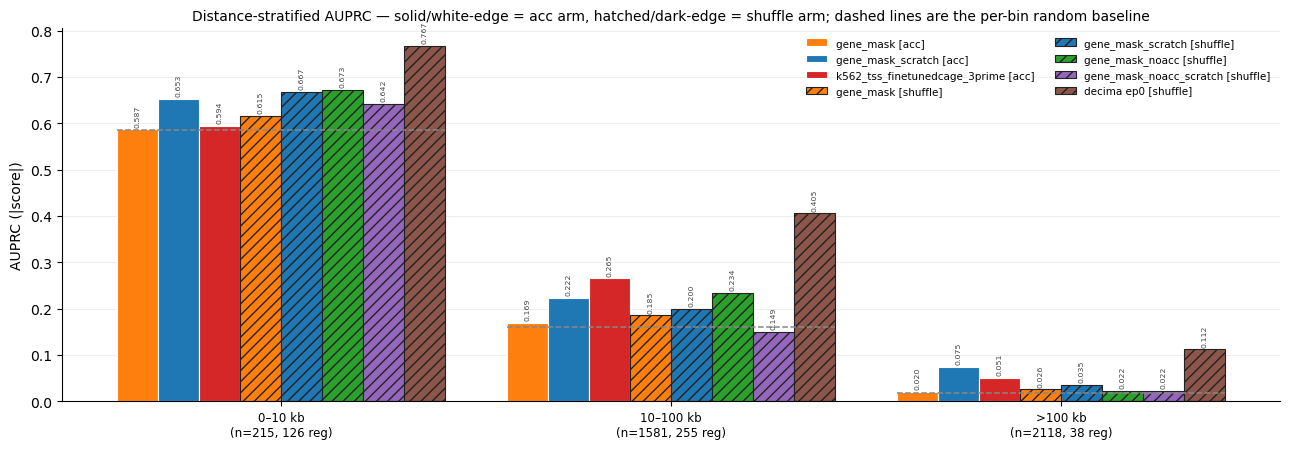

In [22]:
DIST_BINS = [("0–10 kb", lambda d: d <= 10_000),
             ("10–100 kb", lambda d: (d > 10_000) & (d <= 100_000)),
             (">100 kb", lambda d: d > 100_000)]
dist_abs = np.abs(dist)

rows = []
for key in RUN_KEYS:
    d = e2g[key]
    for label, fn in DIST_BINS:
        m = ctx & fn(dist_abs) & ~np.isnan(dist_abs)
        yt = y_true[m]
        if m.sum() == 0 or yt.sum() == 0:
            continue
        prec, rec, _ = precision_recall_curve(yt, np.abs(d["score"][m]))
        rows.append({"model": key[0], "arm": key[1], "bin": label, "N": int(m.sum()),
                     "n_reg": int(yt.sum()), "baseline": yt.mean(), "auprc": auc(rec, prec)})
dist_df = pd.DataFrame(rows)
display(dist_df.pivot_table(index=["model", "arm"], columns="bin", values="auprc").round(4))

# gene_mask and gene_mask_scratch each appear twice (both arms) and share a color within a model,
# so the arm has to carry visually: acc bars are solid with a white edge, shuffle bars are hatched
# with a dark edge so the hatch actually reads. Bars are ordered acc-first, then shuffle.
DIST_KEYS = ([k for k in RUN_KEYS if k[1] == "acc"] + [k for k in RUN_KEYS if k[1] == "shuffle"])

fig, ax = plt.subplots(figsize=(13, 4.6))
labels = [lab for lab, _ in DIST_BINS]
x = np.arange(len(labels))
w = 0.84 / len(DIST_KEYS)
center = (len(DIST_KEYS) - 1) / 2
for i, key in enumerate(DIST_KEYS):
    sub = dist_df[(dist_df["model"] == key[0]) & (dist_df["arm"] == key[1])].set_index("bin")
    vals = [sub.loc[lab, "auprc"] for lab in labels]
    xs = x + (i - center) * w
    ax.bar(xs, vals, w,
           color=COLORS[key[0]], hatch=None if key[1] == "acc" else "///",
           edgecolor="white" if key[1] == "acc" else "#222222", linewidth=0.8,
           label=run_label(key))
    # Label every bar; models present in both arms share a color.
    for xi, v in zip(xs, vals):
        ax.text(xi, v + 0.006, f"{v:.3f}", ha="center", va="bottom", fontsize=5.6,
                rotation=90, color="#444")
base = dist_df.drop_duplicates(["bin"]).set_index("bin")
for xi, lab in zip(x, labels):
    b = base.loc[lab, "baseline"]
    ax.plot([xi - len(DIST_KEYS) * w / 2, xi + len(DIST_KEYS) * w / 2], [b, b], color="#888", linestyle="--", lw=1.1)
ax.set_xticks(x)
ax.set_xticklabels([f"{lab}\n(n={int(base.loc[lab, 'N'])}, {int(base.loc[lab, 'n_reg'])} reg)"
                    for lab in labels], fontsize=8.5)
ax.set_ylabel("AUPRC (|score|)")
ax.set_title("Distance-stratified AUPRC — solid/white-edge = acc arm, hatched/dark-edge = shuffle "
             "arm; dashed lines are the per-bin random baseline", fontsize=10)
ax.legend(frameon=False, fontsize=7.5, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


### 8f. Fine-tuned 3′ RNA model: count versus profile readout

Both heads come from `k562_tss_finetunedcage_3prime`, epoch 27, under the same
accessibility ÷ 100 perturbation (element ± 100 bp).

- **Count:** `count_after - count_before`, the change in predicted `ln(1 + CPM)`.
- **Profile:** the native gene-body sum, scored as
  `ln((sum_after + 1) / (sum_before + 1))`. This sums the model's
  `sqrt(1 + coverage) - 1` profile, not reconstructed coverage. It is the saved
  `delta_body_native * ln(2)`. Its magnitude is a different quantity from the count score.

All curves and table rows below use the **same 3875 evaluated, in-context links with the
full gene body in view** (398 positives); 39 links with truncated genes are excluded from
every row, including the count-head baselines. The existing accessibility-arm models are
recomputed on these same links. Read AUPRC within this panel; its smaller subset means these
numbers need not equal the 3914-link results above. Both the expected repression direction
(`-score`) and the notebook's absolute-score ranking are shown. There is no shuffle result
for the fine-tuned model.


Matched full-gene subset: 3875 pairs, 398 regulated; 39 truncated-gene links excluded from every readout.


,readout,direction,N,n_positive,baseline,auprc
0,gene_mask [count],decrease (-score),3875,398,0.1027,0.2053
1,gene_mask_scratch [count],decrease (-score),3875,398,0.1027,0.1695
2,k562_tss_finetunedcage_3prime [count],decrease (-score),3875,398,0.1027,0.2818
3,k562_tss_finetunedcage_3prime [profile: gene body],decrease (-score),3875,398,0.1027,0.3165
4,gene_mask [count],absolute (|score|),3875,398,0.1027,0.1287
5,gene_mask_scratch [count],absolute (|score|),3875,398,0.1027,0.2398
6,k562_tss_finetunedcage_3prime [count],absolute (|score|),3875,398,0.1027,0.3333
7,k562_tss_finetunedcage_3prime [profile: gene body],absolute (|score|),3875,398,0.1027,0.3777


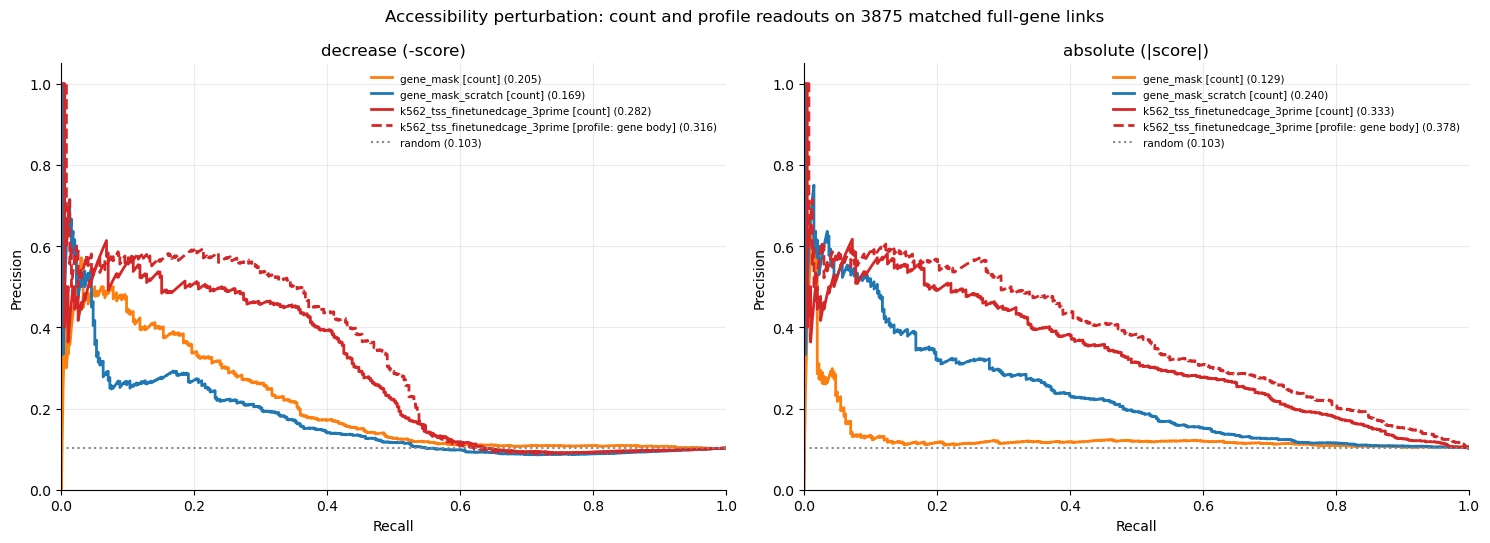

In [23]:
full_gene = ctx & finetuned_evaluated & finetuned_scores["body_full"].to_numpy(bool)
profile_native_score = finetuned_scores["delta_body_native"].to_numpy() * np.log(2)
np.testing.assert_allclose(
    profile_native_score[full_gene],
    np.log((finetuned_scores.loc[full_gene, "body_native_after"].to_numpy() + 1)
           / (finetuned_scores.loc[full_gene, "body_native_before"].to_numpy() + 1)),
    rtol=1e-6, atol=1e-10)
head_scores = {f"{m} [count]": e2g[(m, "acc")]["score"] for m in ARM_MODELS["acc"]}
head_scores[f"{FINETUNED} [profile: gene body]"] = profile_native_score
head_colors = {f"{m} [count]": COLORS[m] for m in ARM_MODELS["acc"]}
head_colors[f"{FINETUNED} [profile: gene body]"] = COLORS[FINETUNED]
yt = y_true[full_gene]
print(f"Matched full-gene subset: {int(full_gene.sum())} pairs, {int(yt.sum())} regulated; "
      f"{int((ctx & ~full_gene).sum())} truncated-gene links excluded from every readout.")
rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (direction, score_fn) in zip(axes, [("decrease (-score)", lambda s: -s),
                                         ("absolute (|score|)", np.abs)]):
    for label, scores in head_scores.items():
        assert np.isfinite(scores[full_gene]).all(), f"{label}: missing full-gene scores"
        prec, rec, _ = precision_recall_curve(yt, score_fn(scores[full_gene]))
        value = auc(rec, prec)
        rows.append({"readout": label, "direction": direction, "N": len(yt),
                     "n_positive": int(yt.sum()), "baseline": yt.mean(), "auprc": value})
        ax.plot(rec, prec, color=head_colors[label], lw=2,
                linestyle="--" if "[profile:" in label else "-",
                label=f"{label} ({value:.3f})")
    ax.axhline(yt.mean(), color="#888", linestyle=":", label=f"random ({yt.mean():.3f})")
    ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.05), title=direction)
    ax.legend(fontsize=7.5, frameon=False, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25)
head_comparison_df = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", None):
    display(head_comparison_df.round(4))
fig.suptitle(f"Accessibility perturbation: count and profile readouts on {len(yt)} matched full-gene links",
             fontsize=12)
fig.tight_layout()
plt.show()


### What to read out of section 8

Points to check once the cells have run, rather than pre-written conclusions:

- **The shuffle-arm 2x2 (§8a-bis) is the new thing in this round.** With
  `gene_mask_scratch` now scored under the shuffle protocol, pretraining and the accessibility
  input are separable *within one perturbation*, which was not possible before. Read the two main
  effects printed under that figure rather than eyeballing the bars, and read both next to
  caveat 1: the epochs are 16 / 27 / 04 / 19, not matched.
- **Pretraining, with accessibility withheld:** `gene_mask_noacc` vs. `gene_mask_noacc_scratch`,
  both in the `shuffle` arm, identical protocol. Read it next to their §1 expression metrics and
  next to caveat 1 — the pretrained run is a 4-epoch model that had already started overfitting.
- **Pretraining, with real ATAC, under the shuffle perturbation:** `gene_mask` vs.
  `gene_mask_scratch` in the `shuffle` arm. The same contrast exists in the `acc` arm; if the two
  arms disagree on its sign, the effect is a property of the perturbation and not of pretraining.
- **Withholding accessibility, at fixed pretraining:** `gene_mask` vs. `gene_mask_noacc`, both in
  the `shuffle` arm. This is the cleanest statement in the section about whether the sequence route
  carries E2G information when the model cannot lean on the ATAC track at all.
- **Decima epoch 0:** compare against the other shuffle models using AUPRC, score direction,
  noise-normalized scores, effect-size correlations, and distance strata. This compares
  architectures under a matched perturbation, not a single training factor.
- **CAGE-to-3′ RNA fine-tune:** its count head joins the expression comparisons and the
  in-context accessibility-arm comparisons. §8f compares its count and gene-body profile
  readouts against the existing count models on identical full-gene links. It sits outside
  the four-model ablation grid and has no shuffle or all-pair result.
- **Pretraining, with real ATAC:** `gene_mask` vs. `gene_mask_scratch` in the `acc` arm.
- **Do not compare across arms.** The numbers that span them are `gene_mask`'s and
  `gene_mask_scratch`'s, and the gap between their two arms is a property of the perturbations,
  not of any model. Two anchors instead of one make that gap measurable rather than assumed.
- **§8c is load-bearing for the whole shuffle arm.** In the previous round the median
  `|score| / sd` sat at 0.71–1.08 — the average element's response to destroying its sequence was
  the same size as the spread between two different shuffles of that same sequence — and `|z|`
  AUPRC collapsed to baseline. If that repeats here, the shuffle arm's AUPRC comes from a minority
  of elements with a large *absolute* response, not from a broad per-element sequence signal, and
  should be quoted with that attached.
- **Sign consistency (§8b) and effect-size magnitude (§8d) are separate failures.** A model can
  rank well on `|score|` while having no usable direction, and every model in the previous round
  had a negligible effect-size `r` despite significant p-values driven by N ≈ 3900.
- **What would settle the noise-floor question.** The shuffle floor is an 11-shuffle estimate;
  raising `--n_shuffles` shrinks the std's own error but not the underlying wobble. The informative
  experiment is a **negative control shuffle** — shuffle a matched-length window at a random
  non-element position the same 11 times — which would say whether the ~1 sd response at real
  elements is any larger than at arbitrary sequence. Nothing in the current output distinguishes
  those two.
